<a href="https://colab.research.google.com/github/vrishinm/2026-Data3001-XIE-G2/blob/main/Lucy_temperature_and_handover.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DATA3001 — Agulhas region: data availability and 7-day pairs

One notebook for Section 2 of the proposal and the first step of the transport model. Region R = [10°E, 45°E] × [45°S, 20°S], boundaries inclusive.

Data: NOAA Global Drifter Program hourly product, version 2.01.1 (Elipot et al., 2016; 2022), accessed via CloudDrift `gdp1h()`. DOI: 10.25921/x46c-3620. Coverage 1987-10-02 to 2022-10-31.

Run top to bottom. The data are loaded once in Section 0 and every later cell reuses them. All numbers used in the README are saved to `gdp_out/results.json`.

In [ ]:
!pip install -q clouddrift

## 0. Setup and data

In [ ]:
# Setup + load the data ONCE (slide 21). Every later cell reuses these arrays,
# so nothing is downloaded twice.
import os, json, time
import numpy as np
import pandas as pd
from clouddrift.datasets import gdp1h

# Region R: greater Agulhas Current system. Boundaries are INCLUSIVE (<=),
# which is how the Week 1 illustration counts records (3,848,969 in R).
west, east, south, north = 10, 45, -45, -20
GRID = 2                 # 2° cells for the transition matrix
OUT = "gdp_out"
os.makedirs(OUT, exist_ok=True)

def load(da, name, tries=5):
    """.values with a few retries: the public S3 store sometimes drops mid-transfer."""
    for i in range(tries):
        try:
            return da.values
        except Exception as e:
            if i == tries - 1:
                raise
            print(f"  {name} failed ({e!r}), retrying ...")
            time.sleep(3 * (i + 1))

t0 = time.time()
if "ds" not in globals():
    ds = gdp1h()
lon = load(ds["lon"], "lon")
lat = load(ds["lat"], "lat")
t_ns = load(ds["time"], "time").astype("datetime64[ns]").astype(np.int64)
rowsize = load(ds["rowsize"], "rowsize").astype(np.int64)
bounds = np.cumsum(rowsize)          # end (exclusive) of each drifter's block of rows
starts = bounds - rowsize
n_obs, n_traj = len(lon), len(rowsize)
assert bounds[-1] == n_obs
assert np.nanmax(lon) <= 180, "expected -180..180 longitudes"
print(f"{n_obs:,} hourly records from {n_traj:,} drifters, loaded in {time.time() - t0:.0f}s")

def as_time(x):
    x = np.asarray(x)
    return x if np.issubdtype(x.dtype, np.datetime64) else pd.to_datetime(x, unit="s").values

def in_box(lo, la, x0, x1, y0, y1):
    return (lo >= x0) & (lo <= x1) & (la >= y0) & (la <= y1)

def cell_of(lo, la, x0, x1, y0, y1, size):
    """Cell number inside a box; np.clip keeps points exactly on the east/north edge in the last column/row."""
    nc, nr = int(np.ceil((x1 - x0) / size)), int(np.ceil((y1 - y0) / size))
    c = np.clip(np.floor((lo - x0) / size).astype(int), 0, nc - 1)
    r = np.clip(np.floor((la - y0) / size).astype(int), 0, nr - 1)
    return r * nc + c, nc, nr

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


197,214,787 hourly records from 19,396 drifters, loaded in 30s


## 1. Data audit

Before trusting any count: missing or out-of-range coordinates, duplicate timestamps, and steps that are not exactly one hour. The 7-day pairs in Section 6 check the real elapsed time instead of assuming 168 rows is always 7 days.

In [ ]:
# 1. Data audit (slide 9: inspect before you trust any count)
one_hour = np.int64(3600 * 10**9)
same_traj = np.ones(n_obs - 1, dtype=bool)
same_traj[bounds[:-1] - 1] = False          # the step from one drifter's last row to the next drifter's first row
dt = np.diff(t_ns)
audit = dict(
    n_obs=int(n_obs), n_traj=int(n_traj),
    missing_lon=int(np.isnan(lon).sum()), missing_lat=int(np.isnan(lat).sum()),
    out_of_range_coords=int(((lon < -180) | (lon > 180) | (lat < -90) | (lat > 90)).sum()),
    duplicate_timestamps_within_traj=int(((dt == 0) & same_traj).sum()),
    non_hourly_steps_within_traj=int(((dt != one_hour) & (dt != 0) & same_traj).sum()),
    consecutive_pairs_within_traj=int(same_traj.sum()),
)
del dt, same_traj
audit["non_hourly_share"] = round(audit["non_hourly_steps_within_traj"] / audit["consecutive_pairs_within_traj"], 6)
print(json.dumps(audit, indent=2))

{
  "n_obs": 197214787,
  "n_traj": 19396,
  "missing_lon": 0,
  "missing_lat": 0,
  "out_of_range_coords": 0,
  "duplicate_timestamps_within_traj": 0,
  "non_hourly_steps_within_traj": 80839,
  "consecutive_pairs_within_traj": 197195391,
  "non_hourly_share": 0.00041
}


## 2. Region choice and pipeline check

The same counting is applied to every candidate box. The East Australian Current example from the course is used to check the pipeline against a published number.

In [ ]:
# 2. Region choice: the same counting applied to every candidate box (Table 1)
def box_stats(x0, x1, y0, y1, size):
    idx = np.nonzero(in_box(lon, lat, x0, x1, y0, y1))[0]
    trj = np.searchsorted(bounds, idx, side="right")
    cid, nc, nr = cell_of(lon[idx], lat[idx], x0, x1, y0, y1, size)
    per_cell = np.bincount(np.unique(cid.astype(np.int64) * 100_000 + trj) // 100_000, minlength=nc * nr)
    occ = per_cell[per_cell > 0]
    return dict(box=f"{x0}..{x1}E, {y0}..{y1}N", grid_deg=size,
                hourly_records=int(len(idx)), distinct_drifters=int(len(np.unique(trj))),
                cells_occupied=int(len(occ)), cells_total=int(nc * nr),
                cells_ge10_drifters=int((occ >= 10).sum()),
                median_drifters_per_cell=int(np.median(occ)) if len(occ) else 0,
                p25=int(np.percentile(occ, 25)) if len(occ) else 0,
                p75=int(np.percentile(occ, 75)) if len(occ) else 0)

# pipeline check: the course's East Australian Current example reports 452 drifters
eac = box_stats(145, 165, -45, -15, 1)
print(f"EAC check: {eac['distinct_drifters']} distinct drifters (slide reports 452)")

boxes = {
    "R (chosen, Agulhas)":            box_stats(west, east, south, north, GRID),
    "Benguela (rejected)":            box_stats(0, 20, -38, -15, GRID),
    "Tighter 10-40E, 45-25S":         box_stats(10, 40, -45, -25, GRID),
    "Source only 20-45E, 40-20S":     box_stats(20, 45, -40, -20, GRID),
}
table1 = pd.DataFrame(boxes).T
print("\nTable 1. Candidate boxes (2° cells)")
print(table1[["hourly_records", "distinct_drifters", "cells_occupied", "cells_total",
              "cells_ge10_drifters", "median_drifters_per_cell", "p25"]].to_string())

EAC check: 452 distinct drifters (slide reports 452)

Table 1. Candidate boxes (2° cells)
                           hourly_records distinct_drifters cells_occupied cells_total cells_ge10_drifters median_drifters_per_cell  p25
R (chosen, Agulhas)               3848969              1149            178         234                 171                      116   76
Benguela (rejected)               2538266               706             97         120                  84                      118   29
Tighter 10-40E, 45-25S            3020671              1051            125         150                 123                      137  101
Source only 20-45E, 40-20S        1827496               628             92         130                  90                       98   70


**Why this is "enough"**

Raw record counts overstate how much information the data contain, because one drifter can stay in the same cell for hundreds of hours. We therefore count the number of different drifters that visit each cell. In R the median 1° cell is visited by 71 different drifters (10th–90th percentile: 24–138), and 614 of 649 occupied cells are visited by at least 10. This suggests transition probabilities can be estimated from many independent realisations rather than from a handful of long tracks. The 1° grid matches the coverage summary in the Week 1 illustration; the transport model starts from 2° cells, which pools more drifters per cell and keeps the transition matrix better supported.

**Why Agulhas over Benguela**

We compared both regions before committing. Benguela has 706 drifters against Agulhas's 1,149, and once we started thinking in terms of independent drifters per cell rather than raw records, that gap mattered more than it first looked. The bigger reason is what each region asks of a transition matrix. In Agulhas the retroflection splits material between two genuinely different outcomes, either back east into the Indian Ocean or west into the Atlantic, so the matrix has something interesting to estimate. Benguela's alongshore/offshore contrast felt like a thinner question to build a whole project around.

## 3. Coverage in R

In [ ]:
# Records in R and which drifter each one belongs to (slide 21: rowsize identifies each drifter's records)
in_idx = np.nonzero(in_box(lon, lat, west, east, south, north))[0]
traj_of_obs = np.searchsorted(bounds, in_idx, side="right")
tr = np.unique(traj_of_obs)
print(f"Hourly records in R: {len(in_idx):,}")
print(f"Distinct drifters in R: {len(tr):,}")
print(f"First record in R: {pd.Timestamp(t_ns[in_idx].min()):%d %b %Y}")

Hourly records in R: 3,848,969
Distinct drifters in R: 1,149
First record in R: 31 Mar 1995


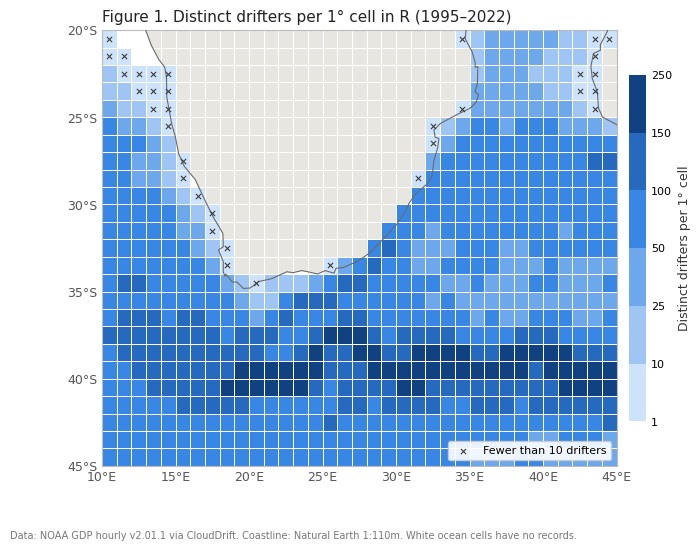

1° cells: occupied 649 of 875 | median drifters 71 (10th-90th: 24-138) | >= 10 drifters: 614
2° cells: occupied 178 of 234 | median drifters 116 (25th: 76) | >= 10 drifters: 171


In [ ]:
# Figure 1: distinct drifters per 1° cell in R (slides 15-16: "How many different drifters support each cell?")
import urllib.request
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Polygon

cell = 1
cell_id, n_cols, n_rows = cell_of(lon[in_idx], lat[in_idx], west, east, south, north, cell)
key = np.unique(cell_id.astype(np.int64) * 100_000 + traj_of_obs)
grid = np.bincount(key // 100_000, minlength=n_rows * n_cols).reshape(n_rows, n_cols).astype(float)
grid[grid == 0] = np.nan

# Land polygons, Natural Earth 1:110m (same coastline source as the Week 1 slides)
try:
    url = "https://raw.githubusercontent.com/nvkelso/natural-earth-vector/master/geojson/ne_110m_land.geojson"
    land = json.load(urllib.request.urlopen(url))
except Exception as e:
    print(f"coastline not loaded ({e!r}); maps drawn without land")
    land = {"features": []}

def draw_land(ax):
    for feat in land["features"]:
        g = feat["geometry"]
        polys = g["coordinates"] if g["type"] == "MultiPolygon" else [g["coordinates"]]
        for p in polys:
            ax.add_patch(Polygon(np.array(p[0]), closed=True, facecolor="#e8e6e1", edgecolor="none", zorder=0))
            ax.add_patch(Polygon(np.array(p[0]), closed=True, fill=False, edgecolor="#6b6a66", linewidth=0.8, zorder=3))

def style_map(ax):
    ax.set_xlim(west, east)
    ax.set_ylim(south, north)
    ax.set_aspect(1 / np.cos(np.deg2rad((north + south) / 2)))
    ax.set_xticks(range(west, east + 1, 5))
    ax.set_yticks(range(south, north + 1, 5))
    ax.set_xticklabels([f"{x}°E" for x in range(west, east + 1, 5)], fontsize=9, color="#555")
    ax.set_yticklabels([f"{-y}°S" for y in range(south, north + 1, 5)], fontsize=9, color="#555")
    ax.tick_params(length=0)
    for s in ax.spines.values():
        s.set_color("#bbb")

# One-hue sequential blue ramp, light = few drifters, dark = many
bins = [1, 10, 25, 50, 100, 150, max(250, int(np.nanmax(grid)) + 1)]
cmap = ListedColormap(["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#104281"])
cmap.set_bad((0, 0, 0, 0))   # transparent, so land shows through
norm = BoundaryNorm(bins, cmap.N)
lon_edges = west + np.arange(n_cols + 1) * cell
lat_edges = south + np.arange(n_rows + 1) * cell

fig, ax = plt.subplots(figsize=(8, 6))
draw_land(ax)
mesh = ax.pcolormesh(lon_edges, lat_edges, grid, cmap=cmap, norm=norm, edgecolor="white", linewidth=0.4, zorder=1)
r, c = np.nonzero(grid < 10)   # cells visited by fewer than 10 distinct drifters
ax.scatter(lon_edges[c] + cell / 2, lat_edges[r] + cell / 2, marker="x", s=14,
           color="#3d3d3a", linewidths=0.8, zorder=4, label="Fewer than 10 drifters")
style_map(ax)
cb = fig.colorbar(mesh, ax=ax, shrink=0.75, pad=0.02)
cb.set_label("Distinct drifters per 1° cell", fontsize=9, color="#333")
cb.ax.tick_params(labelsize=8, length=0)
cb.outline.set_visible(False)
ax.legend(loc="lower right", fontsize=8, frameon=True, framealpha=0.9)
ax.set_title("Figure 1. Distinct drifters per 1° cell in R (1995–2022)", fontsize=11, loc="left", color="#222")
fig.text(0.01, 0.01, "Data: NOAA GDP hourly v2.01.1 via CloudDrift. Coastline: Natural Earth 1:110m. "
         "White ocean cells have no records.", fontsize=7, color="#777")
plt.savefig("fig1_coverage_1deg.png", dpi=200, bbox_inches="tight")
plt.show()

occ = grid[~np.isnan(grid)]
print(f"1° cells: occupied {occ.size} of {n_rows * n_cols} | median drifters {np.median(occ):.0f} "
      f"(10th-90th: {np.percentile(occ, 10):.0f}-{np.percentile(occ, 90):.0f}) | >= 10 drifters: {(occ >= 10).sum()}")
r2 = boxes["R (chosen, Agulhas)"]
print(f"2° cells: occupied {r2['cells_occupied']} of {r2['cells_total']} | median drifters {r2['median_drifters_per_cell']} "
      f"(25th: {r2['p25']}) | >= 10 drifters: {r2['cells_ge10_drifters']}")

## 4. Coverage over years and seasons

Records in R run from 31 Mar 1995 to 31 Oct 2022


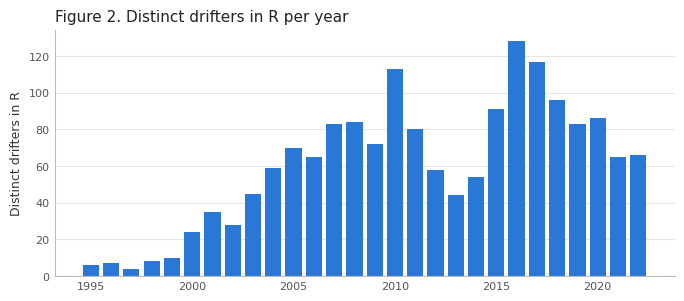

Years with any drifter in R: 28 of 28
Median drifters per year: 65  (min 4 in 1997, max 128 in 2016)
  1995-1999: median 7 drifters per year
  2000-2009: median 62 drifters per year
  2010-2022: median 83 drifters per year

Table 2. Coverage by austral season (1° cells)
      Season  Hourly records  Distinct drifters  Occupied 1° cells  Median drifters per cell  Cells with >= 10 drifters
DJF (summer)          858391                676                634                        18                        533
MAM (autumn)         1012587                704                639                        21                        543
JJA (winter)         1047302                735                637                        21                        560
SON (spring)          930689                714                640                        19                        554


In [ ]:
# Figure 2 + Table 2: coverage across years and seasons (slide 16: "Is coverage sufficient across seasons and years?")
t = pd.DatetimeIndex(t_ns[in_idx])
rec = pd.DataFrame({"traj": traj_of_obs, "year": t.year, "month": t.month})
print(f"Records in R run from {t.min():%d %b %Y} to {t.max():%d %b %Y}")

# ---- Years: distinct drifters present in R each year ----
per_year = rec.groupby("year")["traj"].nunique()
per_year = per_year.reindex(range(per_year.index.min(), per_year.index.max() + 1), fill_value=0)

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.bar(per_year.index, per_year.values, width=0.8, color="#2a78d6")
ax.set_ylabel("Distinct drifters in R", fontsize=9, color="#333")
ax.set_title("Figure 2. Distinct drifters in R per year", fontsize=11, loc="left", color="#222")
ax.tick_params(labelsize=8, length=0, colors="#555")
ax.grid(axis="y", color="#e5e5e5", linewidth=0.8)
ax.set_axisbelow(True)
for s in ["top", "right"]:
    ax.spines[s].set_visible(False)
for s in ["left", "bottom"]:
    ax.spines[s].set_color("#bbb")
plt.savefig("fig2_drifters_per_year.png", dpi=200, bbox_inches="tight")
plt.show()

print(f"Years with any drifter in R: {(per_year > 0).sum()} of {len(per_year)}")
print(f"Median drifters per year: {per_year.median():.0f}  (min {per_year.min()} in {per_year.idxmin()}, "
      f"max {per_year.max()} in {per_year.idxmax()})")
for a, b in [(1995, 1999), (2000, 2009), (2010, 2022)]:
    sel = per_year.loc[a:b]
    print(f"  {a}-{b}: median {sel.median():.0f} drifters per year")

# ---- Seasons (austral): DJF summer, MAM autumn, JJA winter, SON spring ----
season_of = {12: "DJF (summer)", 1: "DJF (summer)", 2: "DJF (summer)",
             3: "MAM (autumn)", 4: "MAM (autumn)", 5: "MAM (autumn)",
             6: "JJA (winter)", 7: "JJA (winter)", 8: "JJA (winter)",
             9: "SON (spring)", 10: "SON (spring)", 11: "SON (spring)"}
rec["season"] = rec["month"].map(season_of)
rec["cell"] = cell_id

rows = []
for s in ["DJF (summer)", "MAM (autumn)", "JJA (winter)", "SON (spring)"]:
    sub = rec[rec["season"] == s]
    per_cell = sub.groupby("cell")["traj"].nunique()
    rows.append({"Season": s, "Hourly records": len(sub), "Distinct drifters": sub["traj"].nunique(),
                 "Occupied 1° cells": len(per_cell), "Median drifters per cell": int(per_cell.median()),
                 "Cells with >= 10 drifters": int((per_cell >= 10).sum())})
table2 = pd.DataFrame(rows)
print("\nTable 2. Coverage by austral season (1° cells)")
print(table2.to_string(index=False))

## 5. Drogue status and how drifters end

Drogue-related variables: ['DragAreaAboveDrogue', 'DragAreaOfDrogue', 'DrogueBallast', 'DrogueCenterDepth', 'DrogueDetectSensor', 'DrogueLength', 'DrogueType', 'drogue_lost_date', 'drogue_status']
drogue_lost_date attrs: {'long_name': 'Date and time of drogue loss'}

Drifters entering R: 1149
  drogue-loss date missing (NaT): 4
  lost on or before deployment:   34
  lost after the record ends:     0
  days drogued after deployment: median 173, 25th-75th 79-360

Five example drifters:
             id     deploy drogue_lost        end
          89770 2010-02-20  2010-04-13 2012-03-22
300234063896840 2017-03-26  2017-06-16 2018-01-27
          70812 2008-02-03  2008-02-23 2011-11-25
         118513 2013-01-01  2013-09-08 2017-01-29
300234064876500        NaT  2021-05-02 2022-02-24

Share of records in R that are drogued (from drogue_lost_date): 33.3%
Share of drifters in R with at least one drogued record in R:  49.4%
Share from the per-record drogue_status flag:                  33.4%
Ag

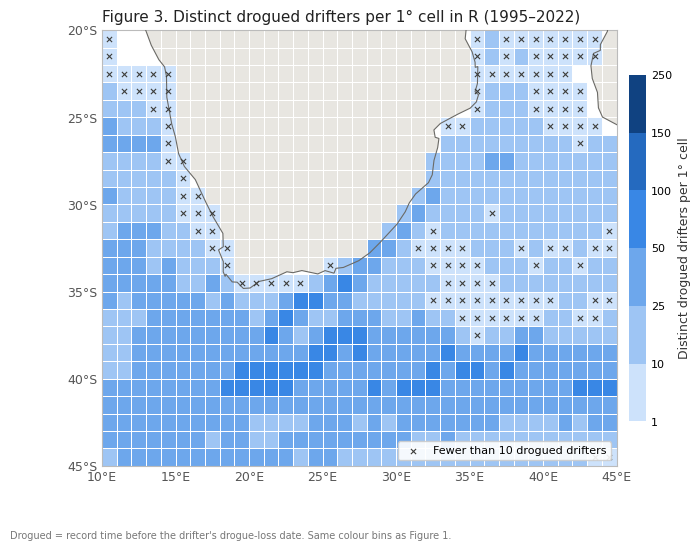

In [ ]:
# Drogue check + Figure 3: drogued drifters per 1° cell
# ---- Part 1: check how the drogue information is stored ----
print("Drogue-related variables:", [v for v in ds.variables if "drog" in v.lower()])
print("drogue_lost_date attrs:", dict(ds.drogue_lost_date.attrs))

meta = pd.DataFrame({
    "id":          ds.id.values[tr],
    "deploy":      as_time(ds.deploy_date.values)[tr],
    "drogue_lost": as_time(ds.drogue_lost_date.values)[tr],
    "end":         as_time(ds.end_date.values)[tr],
})
print(f"\nDrifters entering R: {len(meta)}")
print(f"  drogue-loss date missing (NaT): {meta.drogue_lost.isna().sum()}")
print(f"  lost on or before deployment:   {(meta.drogue_lost <= meta.deploy).sum()}")
print(f"  lost after the record ends:     {(meta.drogue_lost > meta.end).sum()}")
days = (meta.drogue_lost - meta.deploy).dt.days
print(f"  days drogued after deployment: median {days.median():.0f}, "
      f"25th-75th {days.quantile(.25):.0f}-{days.quantile(.75):.0f}")
print("\nFive example drifters:")
print(meta.sample(min(5, len(meta)), random_state=1).to_string(index=False))

# ---- Part 2: drogued share of records in R, two ways ----
t_in = t_ns[in_idx].astype("datetime64[ns]")
lost_rec = as_time(ds.drogue_lost_date.values).astype("datetime64[ns]")[traj_of_obs]
drogued = pd.notnull(lost_rec) & (t_in < lost_rec)
print(f"\nShare of records in R that are drogued (from drogue_lost_date): {drogued.mean():.1%}")
print(f"Share of drifters in R with at least one drogued record in R:  "
      f"{len(np.unique(traj_of_obs[drogued])) / len(tr):.1%}")
if "drogue_status" in ds.variables:
    ds_flag = ds.drogue_status.values[in_idx].astype(bool)
    print(f"Share from the per-record drogue_status flag:                  {ds_flag.mean():.1%}")
    print(f"Agreement between the two methods:                             {(ds_flag == drogued).mean():.1%}")

# ---- Part 3: distinct drogued drifters per 1° cell ----
def drifters_per_cell(mask):
    k = np.unique(cell_id[mask].astype(np.int64) * 100_000 + traj_of_obs[mask])
    g = np.bincount(k // 100_000, minlength=n_rows * n_cols).reshape(n_rows, n_cols).astype(float)
    g[g == 0] = np.nan
    return g

g_all = drifters_per_cell(np.ones(len(in_idx), bool))
g_drg = drifters_per_cell(drogued)
for name, g in [("All drifters", g_all), ("Drogued only", g_drg)]:
    occ = g[~np.isnan(g)]
    print(f"\n{name}: {occ.size} occupied cells | median {np.median(occ):.0f} "
          f"(10th-90th {np.percentile(occ, 10):.0f}-{np.percentile(occ, 90):.0f}) | "
          f">= 10 drifters: {(occ >= 10).sum()} | fewer than 10: {(occ < 10).sum()}")
lost_cells = np.nansum((g_all >= 10) & ~(g_drg >= 10))
print(f"Cells with >= 10 drifters overall but < 10 drogued drifters: {int(lost_cells)}")

# ---- Figure 3: same style and colour bins as Figure 1, drogued drifters only ----
fig, ax = plt.subplots(figsize=(8, 6))
draw_land(ax)
mesh = ax.pcolormesh(lon_edges, lat_edges, g_drg, cmap=cmap, norm=norm, edgecolor="white", linewidth=0.4, zorder=1)
r, c = np.nonzero(g_drg < 10)
ax.scatter(lon_edges[c] + cell / 2, lat_edges[r] + cell / 2, marker="x", s=14, color="#3d3d3a",
           linewidths=0.8, zorder=4, label="Fewer than 10 drogued drifters")
style_map(ax)
cb = fig.colorbar(mesh, ax=ax, shrink=0.75, pad=0.02)
cb.set_label("Distinct drogued drifters per 1° cell", fontsize=9, color="#333")
cb.ax.tick_params(labelsize=8, length=0)
cb.outline.set_visible(False)
ax.legend(loc="lower right", fontsize=8, frameon=True, framealpha=0.9)
ax.set_title("Figure 3. Distinct drogued drifters per 1° cell in R (1995–2022)", fontsize=11, loc="left", color="#222")
fig.text(0.01, 0.01, "Drogued = record time before the drifter's drogue-loss date. Same colour bins as Figure 1.",
         fontsize=7, color="#777")
plt.savefig("fig3_drogued_1deg.png", dpi=200, bbox_inches="tight")
plt.show()

**How we read `typedeath`**

- **0 still alive** — censored: still drifting; the record ends only because the data release has a cut-off date
- **1 ran aground** — ❗️ real endpoint: the flow carried it ashore (e.g. oil washing up on a beach)
- **2 picked up by vessel** — censored: removed by people, unrelated to the flow; it would have kept drifting
- **3 stop transmitting** — censored: transmitter failed, drifter still at sea. ⚠️ Near the coast it may actually have run aground
- **4 sporadic transmissions** — censored: still drifting, but positions are patchy and unreliable
- **5 bad batteries** — censored: power ran out, drifter still at sea
- **6 inactive status** — censored: flagged inactive, whereabouts unknown

In [ ]:
# Table 3: how the drifters in R end (slide 16: "Which exits are observed, and which records end too early?")
td = ds.typedeath.values[tr].astype(int)

# Where is each drifter's very last record: inside R or outside?
last_idx = bounds[tr] - 1
ends_in_R = in_box(lon[last_idx], lat[last_idx], west, east, south, north)

meaning = {0: ("still alive", "censored"), 1: ("ran aground", "real endpoint"),
           2: ("picked up by vessel", "censored"), 3: ("stop transmitting", "censored"),
           4: ("sporadic transmissions", "censored"), 5: ("bad batteries", "censored"),
           6: ("inactive status", "censored")}

rows = []
for k, (name, role) in meaning.items():
    m = td == k
    rows.append({"typedeath": k, "Meaning": name, "Treated as": role,
                 "Drifters": int(m.sum()), "Record ends inside R": int((m & ends_in_R).sum())})
table3 = pd.DataFrame(rows)
table3.loc[len(table3)] = ["", "Total", "", int(len(tr)), int(ends_in_R.sum())]
print(f"Table 3. How the {len(tr):,} drifters that enter R end")
print(table3.to_string(index=False))

print(f"\nDrifters whose record ends outside R (they left R first): {(~ends_in_R).sum()} "
      f"({(~ends_in_R).mean():.1%})")
print(f"Ran aground inside R (real endpoints in R): {((td == 1) & ends_in_R).sum()}")
print(f"'Stop transmitting' inside R: {(ends_in_R & (td == 3)).sum()} (some may be unrecorded groundings)")

Table 3. How the 1,149 drifters that enter R end
typedeath                Meaning    Treated as  Drifters  Record ends inside R
        0            still alive      censored        61                    22
        1            ran aground real endpoint       190                    70
        2    picked up by vessel      censored        27                    12
        3      stop transmitting      censored       857                   203
        4 sporadic transmissions      censored         0                     0
        5          bad batteries      censored         1                     0
        6        inactive status      censored        13                     2
                           Total                    1149                   309

Drifters whose record ends outside R (they left R first): 840 (73.1%)
Ran aground inside R (real endpoints in R): 70
'Stop transmitting' inside R: 203 (some may be unrecorded groundings)


/tmp/ipykernel_5654/2212458321.py:19: Pandas4Warning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. The existing dtype int64 cannot hold the value being set, so the result has dtype object. Cast the object to object before this operation to retain the current behavior.
  table3.loc[len(table3)] = ["", "Total", "", int(len(tr)), int(ends_in_R.sum())]


## 6. Seven-day pairs for the transition matrix

One origin per day; a drifter that leaves R at any hour in the 7 days counts as an exit even if it comes back, and the exit is labelled by the side of R it crossed (west = towards the Atlantic). Output: `gdp_out/pairs7.csv`.

In [ ]:
# 7-day pairs for the transition matrix (README "Building the pairs")
# - one origin per day (00:00 UTC), not every hour: neighbouring hours are near-duplicates
# - a drifter counts as "exited" if it is outside R at ANY hour in the 7 days,
#   even if it comes back (outside is an absorbing state in the matrix)
# - each exit is labelled by the side of R it crossed: west = towards the Atlantic
# - record ends inside R before day 7 -> pair dropped (we don't know where it went)
# Uses the WHOLE tracks of the drifters that enter R (also outside R), otherwise we couldn't see them leave.
H = 7 * 24                      # 7 days = 168 rows on the hourly grid
DAY = np.int64(86_400 * 10**9)  # one day in nanoseconds

rows_tr = np.concatenate([np.arange(starts[j], bounds[j]) for j in tr])
plon, plat, pt = lon[rows_tr], lat[rows_tr], t_ns[rows_tr]
ptraj = np.repeat(tr, rowsize[tr])
row_end = np.repeat(np.cumsum(rowsize[tr]), rowsize[tr])   # end (exclusive) of each row's drifter block

valid = np.isfinite(plon) & np.isfinite(plat)
inR = valid & in_box(plon, plat, west, east, south, north)
cs = np.concatenate([[0], np.cumsum(valid & ~inR)])        # cs[m] = outside rows among rows 0..m-1

n_cells = int(np.ceil((east - west) / GRID)) * int(np.ceil((north - south) / GRID))
EXIT = {"west": n_cells, "east": n_cells + 1, "south": n_cells + 2, "north": n_cells + 3}
def cell2(i):
    return cell_of(plon[i], plat[i], west, east, south, north, GRID)[0]

# origins: inside R, at 00:00 UTC
o = np.nonzero(inR & (pt % DAY == 0))[0]
last = np.minimum(o + H, row_end[o] - 1)

# did it leave R at any hour in the next 7 days? where did it first leave?
exited = (cs[last + 1] - cs[o + 1]) > 0
first_out = np.searchsorted(cs, cs[o + 1] + 1, side="left") - 1
exited &= (pt[np.where(exited, first_out, o)] - pt[o]) <= 7 * DAY

# if it didn't leave: need a position exactly 7 days later (checked by time, not just row offset)
d = o + H
full = d < row_end[o]
d_safe = np.where(full, d, o)
exact = full & ((pt[d_safe] - pt[o]) == 7 * DAY)
stayed = ~exited & exact & inR[d_safe]
keep = exited | stayed

dest = np.full(len(o), -1)
dest[stayed] = cell2(d[stayed])
fo = first_out[exited]
dest[exited] = np.where(plon[fo] < west, EXIT["west"],
               np.where(plon[fo] > east, EXIT["east"],
               np.where(plat[fo] < south, EXIT["south"], EXIT["north"])))

pairs7 = pd.DataFrame({"origin_cell": cell2(o[keep]), "dest": dest[keep],
                       "traj": ptraj[o[keep]], "time": pd.to_datetime(pt[o[keep]]),
                       "obs_row": rows_tr[o[keep]]})
pairs7.to_csv(os.path.join(OUT, "pairs7.csv"), index=False)

n_exit = int(exited.sum())
exit_and_return = int((exited & exact & inR[d_safe]).sum())
per_cell = pairs7.groupby("origin_cell")["traj"].nunique()
pairs_summary = dict(
    daily_origins_in_R=int(len(o)), kept_pairs=int(keep.sum()), dropped_pairs=int((~keep).sum()),
    stayed_in_R=int(stayed.sum()), left_R=n_exit,
    left_by_side={s: int((pairs7.dest == c).sum()) for s, c in EXIT.items()},
    left_and_came_back=exit_and_return,
    cells_with_pairs=int(len(per_cell)), cells_total=n_cells,
    cells_ge10_distinct_drifters=int((per_cell >= 10).sum()),
    median_distinct_drifters_per_cell=int(per_cell.median()) if len(per_cell) else 0,
)
print(json.dumps(pairs_summary, indent=2))
print(f"\n{exit_and_return:,} of {n_exit:,} exits ({exit_and_return / max(n_exit, 1):.1%}) came back by day 7 "
      f"-> these would be counted as 'stayed' if we only looked at day 7")

{
  "daily_origins_in_R": 160500,
  "kept_pairs": 154139,
  "dropped_pairs": 6361,
  "stayed_in_R": 142893,
  "left_R": 11246,
  "left_by_side": {
    "west": 3594,
    "east": 5343,
    "south": 1785,
    "north": 524
  },
  "left_and_came_back": 1448,
  "cells_with_pairs": 177,
  "cells_total": 234,
  "cells_ge10_distinct_drifters": 171,
  "median_distinct_drifters_per_cell": 107
}

1,448 of 11,246 exits (12.9%) came back by day 7 -> these would be counted as 'stayed' if we only looked at day 7


In [ ]:
# check obs_row points at the right start (inside R, same time)
print(pairs7.shape)
print(pairs7.head())
r = pairs7.obs_row.values
print("lon/lat in R:", in_box(lon[r], lat[r], west, east, south, north).all())
print("time matches:", (t_ns[r] == pairs7.time.values.astype("datetime64[ns]").astype(np.int64)).all())


(154139, 5)
   origin_cell  dest  traj       time  obs_row
0            0     1    74 1995-05-30   292694
1            0     1    74 1995-05-31   292718
2            1     2    74 1995-06-01   292742
3            1     2    74 1995-06-02   292766
4            1     2    74 1995-06-03   292790
lon/lat in R: True
time matches: True


## 7. Sea surface temperature at the start of each pair

I use `sst1` rather than total `sst`, because `sst2` is the daily heating cycle and would mostly tell me what time of day the reading was taken, not what water the drifter is in. I only keep flag 5 (estimate and uncertainty both in range). Even then a few flag-5 values were impossible for this region (below 2 °C or above 32 °C), which reminded me that a quality flag isn't the same as a sanity check, so I drop those too.

The last cell checks that the loss is even across seasons and across A, B and C. If one season lost much more data, a "seasonal difference" later on could just be missing data.

In [ ]:
print([v for v in ds.data_vars if "sst" in v])
for v in ["sst1", "flg_sst1", "flg_sst", "err_sst1", "sst2"]:
    if v in ds:
        print("\n", v, ds[v].dtype, ds[v].shape)
        print(ds[v].attrs)


['err_sst', 'err_sst1', 'err_sst2', 'flg_sst', 'flg_sst1', 'flg_sst2', 'sst', 'sst1', 'sst2']

 sst1 float32 (197214787,)
{'comments': 'Estimated near-surface non-diurnal sea water temperature from drifting buoy measurements', 'long_name': 'Fitted non-diurnal sea water temperature', 'units': 'Kelvin'}

 flg_sst1 int8 (197214787,)
{'flag_meanings': 'no-estimate, no-uncertainty-estimate, estimate-not-in-range-uncertainty-not-in-range, estimate-not-in-range-uncertainty-in-range estimate-in-range-uncertainty-not-in-range, estimate-in-range-uncertainty-in-range', 'flag_values': '0, 1, 2, 3, 4, 5', 'long_name': 'Fitted non-diurnal sea water temperature quality flag', 'units': '-'}

 flg_sst int8 (197214787,)
{'flag_meanings': 'no-estimate, no-uncertainty-estimate, estimate-not-in-range-uncertainty-not-in-range, estimate-not-in-range-uncertainty-in-range estimate-in-range-uncertainty-not-in-range, estimate-in-range-uncertainty-in-range', 'flag_values': '0, 1, 2, 3, 4, 5', 'long_name': 'Fitted

In [ ]:
r = pairs7.obs_row.values

sst_all = load(ds["sst1"], "sst1")
flg_all = load(ds["flg_sst1"], "flg_sst1")
pairs7["sst1_C"] = sst_all[r] - 273.15     # Kelvin -> C
pairs7["flg"] = flg_all[r]
del sst_all, flg_all                       # free memory

print(pairs7.flg.value_counts().sort_index())
print("NaN temperature:", pairs7.sst1_C.isna().sum())
print(pairs7.loc[pairs7.flg == 5, "sst1_C"].describe())


flg
0      4862
1         1
2       431
3        10
4        20
5    148815
Name: count, dtype: int64
NaN temperature: 4862
count    148815.000000
mean         17.433054
std           4.989511
min          -1.225006
25%          14.062012
50%          17.831329
75%          20.954010
max          42.173004
Name: sst1_C, dtype: float64


share > 32C: 6.719752713100158e-06  count: 1
share < 2C : 0.0003225481302288076  count: 48
3 drifters
traj
6707     31
12098    11
1783      7
dtype: int64


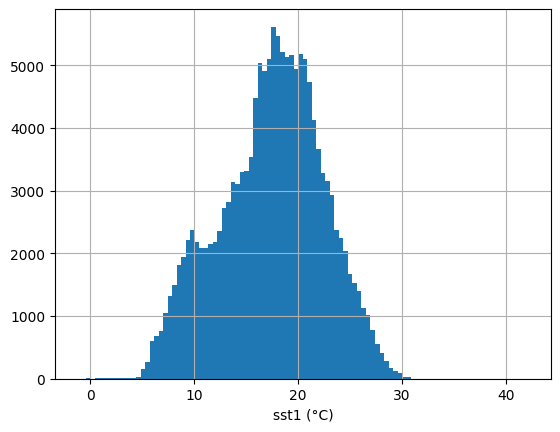

In [ ]:
good = pairs7[pairs7.flg == 5].copy()
print("share > 32C:", (good.sst1_C > 32).mean(), " count:", (good.sst1_C > 32).sum())
print("share < 2C :", (good.sst1_C < 2).mean(),  " count:", (good.sst1_C < 2).sum())

# which drifters do the impossible values come from?
bad = good[(good.sst1_C > 32) | (good.sst1_C < 2)]
print(bad.traj.nunique(), "drifters")
print(bad.groupby("traj").size().sort_values(ascending=False).head(10))

import matplotlib.pyplot as plt
good.sst1_C.hist(bins=100); plt.xlabel("sst1 (°C)"); plt.show()


In [ ]:
season_of = {12:"DJF",1:"DJF",2:"DJF", 3:"MAM",4:"MAM",5:"MAM",
             6:"JJA",7:"JJA",8:"JJA", 9:"SON",10:"SON",11:"SON"}
pairs7["month"]  = pairs7.time.dt.month
pairs7["season"] = pairs7.month.map(season_of)

pairs7["sst_ok"] = (pairs7.flg == 5) & pairs7.sst1_C.between(2, 32)
print("usable:", pairs7.sst_ok.sum(), f"({pairs7.sst_ok.mean():.2%})")

# is the loss even across seasons and across A, B, C?
print(pairs7.groupby("season").sst_ok.agg(["size", "sum", "mean"]))
print(pairs7[pairs7.origin_cell.isin([99, 58, 44])].groupby("origin_cell").sst_ok.agg(["size", "sum", "mean"]))


usable: 148766 (96.51%)
         size    sum      mean
season                        
DJF     34335  33274  0.969099
JJA     42098  40628  0.965081
MAM     40735  39359  0.966221
SON     36971  35505  0.960347
             size   sum      mean
origin_cell                      
44           1468  1443  0.982970
58            815   762  0.934969
99           1081  1022  0.945421


## 8. SST anomaly and faulty sensors

Raw temperature mostly tells me *where* and *when* a drifter started: the Agulhas Current is warm, the south-west is cold, and summer is warmer than winter. Comparing raw temperatures would basically mean comparing locations again, which the matrix already does. So I use an anomaly: start temperature minus the usual temperature for that cell and calendar month. (Section 7 kept 96.5% of starts, and 96–97% in every season, so missing SST shouldn't bias this.)

**Which drifters.** I follow the same rule as the matrix: anything estimated comes from the training drifters only. So the "usual temperature" (the baseline) is built from training drifters, the warm vs cool comparisons use training and validation drifters, and test drifters stay locked for the group's final check. My first version used all drifters because warm vs cool is only an association, but the course brief suggests conditioning transport on warm water. If we later test a warm/cool matrix on held-out drifters, their warm/cool labels shouldn't depend on their own data. The cost is that a baseline from 60% of the drifters leaves some cell-months below the support threshold, so fewer starts get an anomaly (103,743 starts get an anomaly instead of 112,525, about 8% fewer).

The first, simple anomaly below is only used to find broken sensors. Three drifters (1783, 6707, 10764) have long runs of readings around 2 °C in the middle of the Agulhas Current, which can't be real. 6707 is a test drifter, so it is out anyway. I didn't want to pick the other two by eye, so the rule is written in the code (at least 15% of a drifter's starts more than 5 °C off, and at least 30 of them). The last robustness check in Section 9 checks that the result doesn't depend on this rule. They are only removed from the temperature part, because their positions are still fine for the matrix.

For the final anomaly I use a leave-one-drifter-out baseline. A training drifter that sits in one cell for weeks would make up a big part of that cell's average and pull its own anomaly towards zero, so each training drifter is left out of its own baseline (validation drifters aren't in the baseline anyway). A cell-month needs at least 10 starts from at least 5 other drifters; otherwise the "usual temperature" is really just one or two drifters.

In [ ]:
# test drifters stay locked; baselines come from train drifters, comparisons use train + val
SPLIT_URL = "https://raw.githubusercontent.com/vrishinm/2026-Data3001-XIE-G2/main/drifter_split.csv"
split_tab = pd.read_csv(SPLIT_URL)
pairs7["split"] = pairs7.traj.map(dict(zip(split_tab.traj, split_tab.split)))
assert pairs7.split.notna().all()
test_ids = sorted(pairs7.traj[pairs7.split == "test"].unique().tolist())
train_ids = pairs7.traj[pairs7.split == "train"].unique()   # every SST baseline is estimated on these
print("starts by split:", pairs7.split.value_counts().to_dict())

# first, simple anomaly: only used to spot faulty sensors (the real one is built below)

ok = pairs7[pairs7.sst_ok]
base = (ok[ok.traj.isin(train_ids)]
        .groupby(["origin_cell", "month"]).sst1_C
        .agg(base_mean="mean", base_n="size").reset_index())
print("cell-months total:", len(base), "| with n < 10:", (base.base_n < 10).sum())

pairs7 = pairs7.drop(columns=[c for c in ["base_mean", "base_n", "anom"] if c in pairs7]) \
               .merge(base, on=["origin_cell", "month"], how="left")
pairs7["anom"] = np.where(pairs7.sst_ok & (pairs7.base_n >= 10) & (pairs7.split != "test"),
                          pairs7.sst1_C - pairs7.base_mean, np.nan)

print("usable with anomaly:", pairs7.anom.notna().sum())
print(pairs7.anom.describe())

starts by split: {'train': 91153, 'val': 31622, 'test': 31364}
cell-months total: 1987 | with n < 10: 182
usable with anomaly: 117267
count    117267.000000
mean         -0.001436
std           1.549021
min         -18.832508
25%          -0.831097
50%          -0.021177
75%           0.798302
max           9.398221
Name: anom, dtype: float64


In [ ]:
a = pairs7.anom
print("abs(anom) > 5 :", (a.abs() > 5).sum(), "| > 8:", (a.abs() > 8).sum())
print(a.quantile([0.001, 0.01, 0.99, 0.999]))

ext = pairs7[a.abs() > 5][["origin_cell", "traj", "time", "sst1_C", "base_mean", "base_n", "anom"]]
print(ext.groupby("traj").size().sort_values(ascending=False).head(8))
print(ext.sort_values("anom").head(8))


abs(anom) > 5 : 903 | > 8: 119
0.001   -7.023431
0.010   -3.904427
0.990    4.218022
0.999    6.323683
Name: anom, dtype: float32
traj
10764    91
1783     35
3935     23
15280    14
1418     13
1020     13
6526     12
7919     11
dtype: int64
        origin_cell   traj       time    sst1_C  base_mean  base_n       anom
23621            99   1783 2007-06-01  2.264008  21.096516    56.0 -18.832508
23618            99   1783 2007-05-29  4.617004  21.763529    68.0 -17.146524
23625            80   1783 2007-06-05  3.203003  19.896399    79.0 -16.693396
23555            79   1783 2007-03-27  6.968018  23.430361    27.0 -16.462343
23619            99   1783 2007-05-30  6.160004  21.763529    68.0 -15.603525
23546           100   1783 2007-03-01  9.040009  24.336645    61.0 -15.296637
107393           90  12770 2016-08-16  2.291992  16.025789    74.0 -13.733797
23536            81   1783 2007-02-19  8.700012  22.370211    39.0 -13.670198


In [ ]:
# per drifter: what share of its starts have |anomaly| > 5 C
pairs7["extreme"] = pairs7.anom.abs() > 5
drifter_ext = (pairs7[pairs7.anom.notna()].groupby("traj")
     .agg(n=("anom", "size"), n_ext=("extreme", "sum"),
          first=("time", "min"), last=("time", "max")))
drifter_ext["frac"] = drifter_ext.n_ext / drifter_ext.n
print(drifter_ext.sort_values("n_ext", ascending=False).head(12))
print("\ndrifters with frac > 0.10:", (drifter_ext.frac > 0.10).sum(), "| with frac > 0.25:", (drifter_ext.frac > 0.25).sum())


         n  n_ext      first       last      frac
traj                                             
10764  149     91 2013-12-11 2014-05-13  0.610738
1783   174     35 2006-11-07 2007-06-18  0.201149
3935   164     23 2009-02-17 2009-08-11  0.140244
15280  186     14 2019-07-03 2020-01-11  0.075269
1020   142     13 2004-02-08 2004-06-28  0.091549
1418   261     13 2005-04-01 2006-02-02  0.049808
6526   819     12 2010-03-21 2012-08-29  0.014652
12757  253     11 2017-05-16 2018-04-27  0.043478
7919    92     11 2012-10-27 2013-01-26  0.119565
7819   136     10 2010-11-29 2011-04-21  0.073529
11314  268     10 2015-08-05 2016-06-28  0.037313
14051  454     10 2019-07-10 2021-08-03  0.022026

drifters with frac > 0.10: 7 | with frac > 0.25: 1


In [ ]:
# faulty sensors: >= 15% extreme starts and >= 30 of them
bad_sensor = sorted(drifter_ext.index[(drifter_ext.frac >= 0.15) & (drifter_ext.n_ext >= 30)].tolist())
print("faulty SST drifters:", bad_sensor)
assert bad_sensor == [1783, 10764], bad_sensor   # 6707 is faulty too, but it's a test drifter

def build_anom(df, base_ids=None, drop_ids=(), min_n=10, min_drifters=5):
    """anomaly = start sst1 - mean sst1 of the OTHER drifters in the same cell and month"""
    key = ["origin_cell", "month"]
    df = df.drop(columns=[c for c in ["base_mean", "base_n", "base_k", "anom"] if c in df]).copy()
    use = df.sst_ok & ~df.traj.isin(drop_ids)
    src = use if base_ids is None else use & df.traj.isin(base_ids)
    g = df[src]
    tot = g.groupby(key).agg(S=("sst1_C", "sum"), N=("sst1_C", "size"), K=("traj", "nunique"))
    own = g.groupby(key + ["traj"]).agg(s=("sst1_C", "sum"), n=("sst1_C", "size"))
    df = df.merge(tot.reset_index(), on=key, how="left") \
           .merge(own.reset_index(), on=key + ["traj"], how="left")
    df[["s", "n"]] = df[["s", "n"]].fillna(0)
    df["base_n"] = df.N - df.n                 # starts from other drifters
    df["base_k"] = df.K - (df.n > 0)           # number of other drifters
    df["base_mean"] = (df.S - df.s) / df.base_n.where(df.base_n > 0)
    ok = use & (df.base_n >= min_n) & (df.base_k >= min_drifters)
    df["anom"] = np.where(ok, df.sst1_C - df.base_mean, np.nan)
    return df.drop(columns=["S", "N", "K", "s", "n"])

pairs7 = build_anom(pairs7, base_ids=train_ids, drop_ids=bad_sensor + test_ids)   # baseline: train; anomaly: train + val
alt = build_anom(pairs7, drop_ids=bad_sensor + test_ids)                          # only to show what the train-only baseline costs
print("starts with an anomaly | baseline from train:", pairs7.anom.notna().sum(), "| from train + val:", alt.anom.notna().sum())
del alt                                                                            # free memory
print("usable with anomaly:", pairs7.anom.notna().sum())
print(pairs7.anom.describe())
print("abs(anom) > 5:", (pairs7.anom.abs() > 5).sum(), "| > 8:", (pairs7.anom.abs() > 8).sum())
print(pairs7.anom.quantile([0.001, 0.01, 0.99, 0.999]))


faulty SST drifters: [1783, 10764]
starts with an anomaly | baseline from train: 103743 | from train + val: 112525
usable with anomaly: 103743
count    103743.000000
mean         -0.018867
std           1.679692
min         -13.733798
25%          -0.987429
50%          -0.038536
75%           0.908927
max           9.370849
Name: anom, dtype: float64
abs(anom) > 5: 975 | > 8: 21
0.001   -5.949429
0.010   -4.228557
0.990    4.470948
0.999    6.576100
Name: anom, dtype: float64


## 9. Warm vs cool starts at A, B and C (7 days)

My first plan was to compare west/east exit probabilities, but none of the starts in A, B or C leave R within 7 days, so there's nothing to compare at 7 days. Instead I use the 7-day east–west displacement (km, + = east) as the short-term measure, and look at real exits at 91 days in Section 12. Warm = anomaly above 0.

One thing worried me: a 2° cell is about 200 km wide, but the Agulhas core is only tens of km wide and is both warmer and faster. So a "warm" start might just mean "started in the core", and a warm effect would really be a position effect. The next cell checks this in three ways: where warm and cool starts sit inside the cell, a finer 1° baseline, and start position as a control in the regression.

In [ ]:
# 7-day displacement (km) from the start, using obs_row
r0 = pairs7.obs_row.values
r7 = r0 + 7 * 24
has7 = r7 < bounds[pairs7.traj.values]          # don't run into the next drifter
r7s = np.where(has7, r7, r0)
has7 &= (t_ns[r7s] - t_ns[r0]) == 7 * DAY        # exactly 7 days later
pairs7["dx_km"] = np.where(has7, (lon[r7s] - lon[r0]) * 111.32 * np.cos(np.deg2rad(lat[r0])), np.nan)
pairs7["dy_km"] = np.where(has7, (lat[r7s] - lat[r0]) * 110.57, np.nan)

pairs7["warm"] = (pairs7.anom > 0).where(pairs7.anom.notna())   # NaN if no anomaly
pairs7["outcome"] = pairs7.dest.map({v: k for k, v in EXIT.items()}).fillna("stayed")

sub = pairs7[pairs7.anom.notna() & pairs7.origin_cell.isin([99, 58, 44])]
print(pd.crosstab([sub.origin_cell, sub.warm], sub.outcome, margins=True))
print(sub.groupby(["origin_cell", "warm"]).agg(pairs=("traj", "size"), drifters=("traj", "nunique"),
                                                dx_mean=("dx_km", "mean"), dy_mean=("dy_km", "mean"),
                                                dx_n=("dx_km", "count")).round(1))


outcome            stayed   All
origin_cell warm               
44          False     565   565
            True      542   542
58          False     323   323
            True      290   290
99          False     415   415
            True      387   387
All                  2522  2522
                   pairs  drifters  dx_mean  dy_mean  dx_n
origin_cell warm                                          
44          False    565        76     44.1     -0.3   565
            True     542        87     87.9     15.5   542
58          False    323        71    -32.2    -46.9   323
            True     290        91    -52.4     -2.8   290
99          False    415        53    -74.4    -49.0   415
            True     387        82   -154.8   -121.3   387


In [ ]:
import statsmodels.formula.api as smf

# start position relative to the centre of its 2-degree cell (km)
nx = int(np.ceil((east - west) / GRID))
r0 = pairs7.obs_row.values
lon0, lat0 = lon[r0], lat[r0]
col, row = pairs7.origin_cell.values % nx, pairs7.origin_cell.values // nx
pairs7["x_off_km"] = (lon0 - (west + GRID * col + GRID / 2)) * 111.32 * np.cos(np.deg2rad(lat0))
pairs7["y_off_km"] = (lat0 - (south + GRID * row + GRID / 2)) * 110.57

def loo_anom(df, key, use, min_n, min_k, base=None):
    """same anomaly as build_anom, but for any grouping (used for 1-degree cells); base = rows the baseline may use"""
    g = df[use if base is None else use & base]
    tot = g.groupby(key).agg(S=("sst1_C", "sum"), N=("sst1_C", "size"), K=("traj", "nunique"))
    own = g.groupby(key + ["traj"]).agg(s=("sst1_C", "sum"), n=("sst1_C", "size"))
    m = (df[key + ["traj", "sst1_C"]].merge(tot.reset_index(), on=key, how="left")
                                      .merge(own.reset_index(), on=key + ["traj"], how="left"))
    m[["s", "n"]] = m[["s", "n"]].fillna(0)
    bn, bk = m.N - m.n, m.K - (m.n > 0)
    base = (m.S - m.s) / bn.where(bn > 0)
    ok = use.values & (bn >= min_n).values & (bk >= min_k).values
    return pd.Series(np.where(ok, m.sst1_C.values - base.values, np.nan), index=df.index)

use = pairs7.sst_ok & ~pairs7.traj.isin(bad_sensor + test_ids)
pairs7["cell1"] = cell_of(lon0, lat0, west, east, south, north, 1)[0]
pairs7["anom1"] = loo_anom(pairs7, ["cell1", "month"], use, min_n=5, min_k=3,
                          base=pairs7.traj.isin(train_ids))

names = {99: "A", 58: "B", 44: "C"}
s = pairs7[pairs7.origin_cell.isin(names) & pairs7.anom.notna() & pairs7.anom1.notna()].copy()
s["cell"] = s.origin_cell.map(names)
s["warm2"], s["warm1"] = (s.anom > 0).astype(int), (s.anom1 > 0).astype(int)

print("(a) mean position of warm vs cool starts inside the cell (km from centre)")
print(s.groupby(["cell", "warm2"])[["x_off_km", "y_off_km"]].mean().round(1))

print("\n(b) warm minus cool 7-day dx (km), 2-degree vs 1-degree baseline")
rows = []
for c, d in s.groupby("cell"):
    gap = lambda w: d.loc[d[w] == 1, "dx_km"].mean() - d.loc[d[w] == 0, "dx_km"].mean()
    rows.append({"cell": c, "pairs": len(d), "drifters": d.traj.nunique(),
                 "gap_2deg": round(gap("warm2"), 1), "gap_1deg": round(gap("warm1"), 1),
                 "same_label": round((d.warm1 == d.warm2).mean(), 2)})
print(pd.DataFrame(rows).to_string(index=False))

print("\n(c) dx_km ~ warm (+ position in cell), SE clustered by drifter")
rows = []
for c, d in s.groupby("cell"):
    for f in ["dx_km ~ warm2", "dx_km ~ warm2 + x_off_km + y_off_km"]:
        fit = smf.ols(f, data=d).fit(cov_type="cluster", cov_kwds={"groups": d.traj})
        lo, hi = fit.conf_int().loc["warm2"]
        rows.append({"cell": c, "model": "with position" if "off" in f else "warm only",
                     "warm_coef": round(fit.params["warm2"], 1), "ci95": f"[{lo:.1f}, {hi:.1f}]"})
print(pd.DataFrame(rows).to_string(index=False))


(a) mean position of warm vs cool starts inside the cell (km from centre)
            x_off_km  y_off_km
cell warm2                    
A    0           7.1     -31.6
     1          -0.6       5.5
B    0          -6.8      16.8
     1           2.8      -4.6
C    0           4.9      -1.5
     1          -6.5       9.2

(b) warm minus cool 7-day dx (km), 2-degree vs 1-degree baseline
cell  pairs  drifters  gap_2deg  gap_1deg  same_label
   A    727        94     -57.8     -21.0        0.92
   B    476       112     -30.3     -34.5        0.82
   C    933       120      36.9      29.9        0.88

(c) dx_km ~ warm (+ position in cell), SE clustered by drifter
cell         model  warm_coef           ci95
   A     warm only      -57.8 [-114.5, -1.1]
   A with position      -10.6  [-65.0, 43.8]
   B     warm only      -30.3  [-91.1, 30.4]
   B with position      -36.2 [-100.4, 28.1]
   C     warm only       36.9    [0.4, 73.5]
   C with position       41.8    [6.0, 77.6]


### Robustness checks

After controlling for position, C was the only cell with a warm effect left, so before believing it I tried to break it. Warm and cool starts at C don't come from the same kind of drifters: in table (a), warm starts are on average about 2.6 years earlier and less often drogued. So I add month, year and drogue to the model. I also try a continuous anomaly and terciles instead of a 0/1 split, give each drifter one vote, drop one drifter at a time, and fit drogued and undrogued drifters separately.

Daily starts from the same drifter are close to repeats of each other, so standard errors are clustered by drifter, and the bootstrap resamples whole drifters rather than pairs. Otherwise the CIs would look much narrower than they should. The last cell checks that my faulty-sensor rule isn't what creates the result.

In [ ]:
lost = as_time(ds.drogue_lost_date.values).astype("datetime64[ns]")
t_start = pairs7.time.values.astype("datetime64[ns]")
pairs7["drogued"] = (t_start < lost[pairs7.traj.values]).astype(int)   # missing loss date -> undrogued
s["drogued"] = pairs7.loc[s.index, "drogued"].values
s["year"] = s.time.dt.year
s = s[s.dx_km.notna()].copy()

print("(a) are warm and cool starts comparable?")
print(s.groupby(["cell", "warm2"]).agg(pairs=("traj", "size"), drifters=("traj", "nunique"),
      mean_year=("year", "mean"), drogued_share=("drogued", "mean")).round(2))

def coef(d, f, term):
    m = smf.ols(f, data=d).fit(cov_type="cluster", cov_kwds={"groups": d.traj})
    lo, hi = m.conf_int().loc[term]
    return m.params[term], lo, hi

FULL = "dx_km ~ warm2 + x_off_km + y_off_km + C(month) + year + drogued"
models = [("position only", "dx_km ~ warm2 + x_off_km + y_off_km", "warm2"),
          ("+ month, year, drogue", FULL, "warm2"),
          ("continuous anomaly, km per 1 C", FULL.replace("warm2", "anom"), "anom")]
rows = []
for c, d in s.groupby("cell"):
    for name, f, term in models:
        b, lo, hi = coef(d, f, term)
        rows.append({"cell": c, "model": name, "coef": round(b, 1), "ci95": f"[{lo:.1f}, {hi:.1f}]"})
    # warmest third vs coolest third
    t = d.assign(q=pd.qcut(d.anom, 3, labels=False))
    t = t[t.q != 1].assign(warm2=lambda x: (x.q == 2).astype(int))
    b, lo, hi = coef(t, FULL, "warm2")
    rows.append({"cell": c, "model": "terciles (top vs bottom third)", "coef": round(b, 1), "ci95": f"[{lo:.1f}, {hi:.1f}]"})
print("\n(b) warm effect on 7-day east-west displacement (km)")
print(pd.DataFrame(rows).to_string(index=False))

print("\n(c) one vote per drifter")
g = s.groupby(["cell", "traj", "warm2"]).dx_km.mean().reset_index()
dw = g.groupby(["cell", "warm2"]).dx_km.mean().unstack()
dw["gap_drifter_weighted"] = dw[1] - dw[0]
print(dw.round(1))

print("\n(d) leave one drifter out")
rows = []
for c, d in s.groupby("cell"):
    base = smf.ols(FULL, data=d).fit().params["warm2"]
    ests = {j: smf.ols(FULL, data=d[d.traj != j]).fit().params["warm2"] for j in d.traj.unique()}
    e = pd.Series(ests)
    rows.append({"cell": c, "full": round(base, 1), "min": round(e.min(), 1), "max": round(e.max(), 1),
                 "most_influential_drifter": int((e - base).abs().idxmax()),
                 "share_of_runs_same_sign": round((np.sign(e) == np.sign(base)).mean(), 2)})
print(pd.DataFrame(rows).to_string(index=False))


(a) are warm and cool starts comparable?
            pairs  drifters  mean_year  drogued_share
cell warm2                                           
A    0        378        52    2013.73           0.31
     1        349        76    2014.09           0.34
B    0        251        67    2012.63           0.33
     1        225        82    2014.65           0.30
C    0        486        73    2012.68           0.38
     1        447        79    2010.08           0.32

(b) warm effect on 7-day east-west displacement (km)
cell                          model  coef           ci95
   A                  position only -10.6  [-65.0, 43.8]
   A          + month, year, drogue -23.8  [-72.2, 24.5]
   A continuous anomaly, km per 1 C   5.8  [-12.2, 23.9]
   A terciles (top vs bottom third)  29.2  [-27.3, 85.7]
   B                  position only -36.2 [-100.4, 28.1]
   B          + month, year, drogue -38.8 [-103.3, 25.7]
   B continuous anomaly, km per 1 C -15.2   [-32.7, 2.3]
   B terciles (to

In [ ]:
from patsy import dmatrices
rng = np.random.default_rng(3001)
SUB = "dx_km ~ warm2 + x_off_km + y_off_km + C(month) + year"

print("(1) drogued and undrogued drifters separately")
rows = []
for c, d in s.groupby("cell"):
    for lab, dd in [("drogued", d[d.drogued == 1]), ("undrogued", d[d.drogued == 0])]:
        b, lo, hi = coef(dd, SUB, "warm2")
        rows.append({"cell": c, "subset": lab, "pairs": len(dd), "drifters": dd.traj.nunique(),
                     "warm_coef": round(b, 1), "ci95": f"[{lo:.1f}, {hi:.1f}]"})
print(pd.DataFrame(rows).to_string(index=False))

def drifter_bootstrap(d, f, term, B=1000):
    """resample whole drifters, refit by least squares, return estimate, 95% CI, share > 0"""
    y, X = dmatrices(f, d, return_type="dataframe")
    j = X.columns.get_loc(term)
    y, X = y.values.ravel(), X.values
    ids = d.traj.values
    uniq = np.unique(ids)
    rows_of = {u: np.flatnonzero(ids == u) for u in uniq}
    est = np.empty(B)
    for k in range(B):
        pick = rng.choice(uniq, size=len(uniq), replace=True)
        idx = np.concatenate([rows_of[u] for u in pick])
        est[k] = np.linalg.lstsq(X[idx], y[idx], rcond=None)[0][j]
    full = np.linalg.lstsq(X, y, rcond=None)[0][j]
    return full, np.percentile(est, [2.5, 97.5]), (est > 0).mean()

print("\n(2) whole-drifter bootstrap, full model")
rows = []
fig_7d = []                                   # kept for the figure in section 12
for c, d in s.groupby("cell"):
    full, (lo, hi), pos = drifter_bootstrap(d, FULL, "warm2")
    fig_7d.append({"cell": c, "est": full, "lo": lo, "hi": hi})
    rows.append({"cell": c, "warm_coef": round(full, 1), "boot_ci95": f"[{lo:.1f}, {hi:.1f}]",
                 "share_of_resamples_positive": round(pos, 3)})
print(pd.DataFrame(rows).to_string(index=False))


(1) drogued and undrogued drifters separately
cell    subset  pairs  drifters  warm_coef            ci95
   A   drogued    237        28      -93.1 [-166.2, -20.0]
   A undrogued    490        72      -19.7   [-68.1, 28.7]
   B   drogued    150        42      -34.7  [-111.5, 42.1]
   B undrogued    326        73      -51.8  [-140.2, 36.7]
   C   drogued    328        41       33.8   [-22.9, 90.5]
   C undrogued    605        87       17.9   [-22.5, 58.3]

(2) whole-drifter bootstrap, full model
cell  warm_coef      boot_ci95  share_of_resamples_positive
   A      -23.8  [-83.2, 25.9]                        0.148
   B      -38.8 [-106.1, 22.2]                        0.115
   C       14.7  [-16.8, 51.4]                        0.821


In [ ]:
# remove nobody / our rule / a much looser rule, rebuilding the anomaly each time
strict = sorted(drifter_ext.index[(drifter_ext.frac >= 0.05) & (drifter_ext.n_ext >= 10)].tolist())
options = {"keep all (remove 0)": [], f"main (remove {len(bad_sensor)})": bad_sensor,
           f"strict (remove {len(strict)})": strict}
print("strict rule removes:", strict)

rows = []
for name, drop in options.items():
    p = build_anom(pairs7, base_ids=train_ids, drop_ids=list(drop) + test_ids)
    p = p[p.origin_cell.isin(names) & p.anom.notna() & p.dx_km.notna()].copy()
    p["cell"] = p.origin_cell.map(names)
    p["warm2"] = (p.anom > 0).astype(int)
    p["year"] = p.time.dt.year
    for c, t in p.groupby("cell"):
        b, (lo, hi), pos = drifter_bootstrap(t, FULL, "warm2", B=500)
        rows.append({"option": name, "cell": c, "pairs": len(t), "drifters": t.traj.nunique(),
                     "warm_coef": round(b, 1), "boot_ci95": f"[{lo:.1f}, {hi:.1f}]",
                     "share_positive": round(pos, 3)})
print("\nwarm effect on 7-day east-west displacement (km)")
print(pd.DataFrame(rows).sort_values(["cell", "option"]).to_string(index=False))


strict rule removes: [1020, 1783, 3935, 7819, 7919, 10764, 15280, 19081]

warm effect on 7-day east-west displacement (km)
             option cell  pairs  drifters  warm_coef     boot_ci95  share_positive
keep all (remove 0)    A    809       101      -33.6  [-89.8, 8.0]           0.054
    main (remove 2)    A    802        99      -30.5 [-87.2, 14.7]           0.082
  strict (remove 8)    A    799        98      -28.3 [-82.0, 22.6]           0.118
keep all (remove 0)    B    618       124      -23.1 [-82.3, 24.1]           0.170
    main (remove 2)    B    613       122      -25.8 [-79.9, 25.7]           0.186
  strict (remove 8)    B    612       121      -28.5 [-83.5, 23.7]           0.156
keep all (remove 0)    C   1107       131       26.4  [-3.6, 62.6]           0.956
    main (remove 2)    C   1107       131       26.4  [-4.7, 62.6]           0.948
  strict (remove 8)    C   1091       129       23.5  [-5.2, 59.4]           0.950


**What I take from Section 9**
- **A:** the raw gap (warm starts about 58 km further west) is mostly position: with start position in the model it drops to −10.6 km [−65, 44], and the full model gives −23.8 km [−83, 26]. No clear effect.
- **B:** no clear warm effect (−38.8 km [−106, 22]).
- **C:** warm starts drift further east, but how much depends on what I control for. With position only it's +41.8 km [6, 78]; adding month, year and drogue brings it down to +14.7 km [−17, 51], with 82% of resamples positive. Warm starts at C are on average about 2.6 years earlier than cool ones, so part of the gap looks like a difference between years rather than temperature. The sample matters too: the sensor-rule check doesn't need a 1° anomaly, keeps more starts, and gives about +26 km.
- So every version leans east, but none of the full-model intervals excludes 0. My first version (all drifters) gave +28 km with 97% of resamples positive; with the train-only baseline it is weaker and less certain, so I'd call it a weak lean, not a finding.

## 10. Handover files

`pairs7.csv` (with `obs_row`) and `drifter_ids.csv`, one row per drifter, used for the group's 60/20/20 train/validation/test split.

In [ ]:
p = pd.read_csv(os.path.join(OUT, "pairs7.csv"), parse_dates=["time"])
assert list(p.columns) == ["origin_cell", "dest", "traj", "time", "obs_row"], p.columns
assert len(p) == 154139

# one row per drifter with at least one pair (used for the train/val/test split)
gdp_id = load(ds["id"], "id")
ids = (p.assign(exited=p.dest >= n_cells)
         .groupby("traj")
         .agg(n_pairs=("dest", "size"), n_exits=("exited", "sum"),
              n_origin_cells=("origin_cell", "nunique"),
              first_origin=("time", "min"), last_origin=("time", "max"))
         .reset_index())
ids.insert(1, "gdp_id", gdp_id[ids.traj.values])
ids.to_csv(os.path.join(OUT, "drifter_ids.csv"), index=False)

print(f"pairs7.csv: {len(p):,} pairs, columns {list(p.columns)}")
print(f"drifter_ids.csv: {len(ids):,} drifters, {ids.n_pairs.sum():,} pairs in total")
print(ids.head())


pairs7.csv: 154,139 pairs, columns ['origin_cell', 'dest', 'traj', 'time', 'obs_row']
drifter_ids.csv: 1,126 drifters, 154,139 pairs in total
   traj   gdp_id  n_pairs  n_exits  n_origin_cells first_origin last_origin
0    74  7722587      157       22              21   1995-05-30  1996-01-02
1    76  7722589       59       26               3   1995-07-23  1995-10-05
2    77  7722583      139        7               9   1995-09-29  1996-03-13
3    78  7722593       22        0               2   1995-11-10  1995-12-01
4    79  7722585      200        7              29   1995-10-13  1996-04-29


## 11. Matrix vs observed outcomes at longer horizons

The poster's 91-day numbers (17.8% west from B, 38.7% east from C) come from multiplying the 7-day matrix 13 times. That assumes a drifter's next week depends only on the cell it's in now. Before using 91 days for temperature, I wanted to check whether that holds.

`pairs7` has a row for every drifter on every day it is in R, so I can follow one start week by week through its own pairs and see where it really is after 28, 56 or 91 days, without the matrix. The exit rule is the same as in the matrix. If a week is missing (the record ended or has a gap), the start is left out ("censored").

To keep it a fair test, the matrix is fitted on the training drifters from our group split and checked against the validation drifters only (test drifters are not used). The CIs resample whole drifters on both sides. One thing could bias the observed shares: a start that exits early still counts even if its record stops later, but a start that stays inside has to last all 13 weeks. So the cell after it redoes the 91-day shares with censored starts kept in until the week they are lost (cumulative incidence), using training and validation drifters only.

In [ ]:
def chain_outcomes(pairs, start_cell, weeks):
    """follow each start week by week through its own 7-day pairs; returns inR / exit side / censored"""
    t_ns = pairs.time.values.astype("datetime64[ns]").astype(np.int64)
    look = dict(zip(zip(pairs.traj.values, t_ns), pairs.dest.values))
    WEEK = np.int64(7 * 86_400 * 10**9)
    side = {v: k for k, v in EXIT.items()}
    sel = np.flatnonzero(pairs.origin_cell.values == start_cell)
    res = []
    for i in sel:
        tj, t, out = pairs.traj.values[i], t_ns[i], "inR"
        for _ in range(weeks):
            dst = look.get((tj, t))
            if dst is None:            # record ended or gap
                out = "censored"; break
            if dst >= n_cells:
                out = side[dst]; break
            t += WEEK
        res.append(out)
    return pd.DataFrame({"traj": pairs.traj.values[sel], "out": res})

def matrix_from(pairs, w=None):
    """same matrix as the poster; w = optional weight per pair (for the bootstrap)"""
    K = n_cells + 4
    C = np.zeros((K, K))
    np.add.at(C, (pairs.origin_cell.values, pairs.dest.values), 1 if w is None else w)
    for e in EXIT.values():
        C[e, e] = 1
    empty = C.sum(1) == 0
    C[empty, empty] = 1
    return C / C.sum(1, keepdims=True)

# group split: matrix from train drifters, compared with val drifters (test not used)
SPLIT_URL = "https://raw.githubusercontent.com/vrishinm/2026-Data3001-XIE-G2/main/drifter_split.csv"
split_tab = pd.read_csv(SPLIT_URL)
pairs7["split"] = pairs7.traj.map(dict(zip(split_tab.traj, split_tab.split)))
assert pairs7.split.notna().all()
train13, val13 = pairs7[pairs7.split == "train"], pairs7[pairs7.split == "val"]

cells_abc = {"A": 99, "B": 58, "C": 44}
horizons = [28, 56, 91]
B13 = 500
rng13 = np.random.default_rng(13)

tr_ids = np.unique(train13.traj.values)
tr_pos = pd.Series(np.arange(len(tr_ids)), index=tr_ids)[train13.traj.values].values
P_train = matrix_from(train13)
P_boot = [matrix_from(train13, np.bincount(rng13.integers(0, len(tr_ids), len(tr_ids)),
                                           minlength=len(tr_ids))[tr_pos]) for _ in range(B13)]

rows = []
for name, cid in cells_abc.items():
    for days in horizons:
        k = days // 7
        o = chain_outcomes(val13, cid, k)
        unc = o[o.out != "censored"]
        ids = np.unique(unc.traj.values)
        pos_v = pd.Series(np.arange(len(ids)), index=ids)[unc.traj.values].values
        for s_ in ["west", "east"]:
            hit = (unc.out == s_).values.astype(float)
            obs, mat = 100 * hit.mean(), 100 * np.linalg.matrix_power(P_train, k)[cid, EXIT[s_]]
            gaps = []
            for Pb in P_boot:
                w = np.bincount(rng13.integers(0, len(ids), len(ids)), minlength=len(ids))[pos_v]
                gaps.append(100 * (hit * w).sum() / w.sum()
                            - 100 * np.linalg.matrix_power(Pb, k)[cid, EXIT[s_]])
            lo, hi = np.percentile(gaps, [2.5, 97.5])
            rows.append({"cell": name, "days": days, "side": s_,
                         "observed_val_%": round(obs, 1), "matrix_train_%": round(mat, 1),
                         "obs_minus_matrix": round(obs - mat, 1), "boot_ci95": f"[{lo:.1f}, {hi:.1f}]",
                         "starts_seen": f"{len(unc)}/{len(o)}", "val_drifters": len(ids)})
tab13 = pd.DataFrame(rows)
del P_boot                                     # 500 bootstrap matrices, no longer needed
print("matrix (train drifters) vs observed (val drifters), exit share by day")
print(tab13.to_string(index=False))


matrix (train drifters) vs observed (val drifters), exit share by day
cell  days side  observed_val_%  matrix_train_%  obs_minus_matrix     boot_ci95 starts_seen  val_drifters
   A    28 west             0.0             0.0              -0.0  [-0.0, -0.0]     162/164            22
   A    28 east             0.0             0.0              -0.0  [-0.0, -0.0]     162/164            22
   A    56 west             1.2             0.4               0.8   [-0.5, 3.7]     160/164            22
   A    56 east             3.8             1.5               2.2  [-1.8, 10.8]     160/164            22
   A    91 west             5.0             3.2               1.9   [-2.2, 8.7]     159/164            21
   A    91 east             6.9            11.6              -4.7  [-11.8, 6.3]     159/164            21
   B    28 west             2.3             0.8               1.5   [-1.0, 5.6]     174/196            32
   B    28 east             0.0             0.0              -0.0  [-0.0, -0.0]   

In [ ]:
# 91-day exits again, keeping censored starts until the week they are lost (train + val drifters)
def chain_weeks(pairs, start_cell, weeks):
    """like chain_outcomes, but also returns the week each start exits or is censored"""
    t_ns = pairs.time.values.astype("datetime64[ns]").astype(np.int64)
    look = dict(zip(zip(pairs.traj.values, t_ns), pairs.dest.values))
    WEEK = np.int64(7 * 86_400 * 10**9)
    side = {v: k for k, v in EXIT.items()}
    sel = np.flatnonzero(pairs.origin_cell.values == start_cell)
    out, wk = [], []
    for i in sel:
        tj, t, o, k_end = pairs.traj.values[i], t_ns[i], "inR", weeks
        for k in range(weeks):
            dst = look.get((tj, t))
            if dst is None:
                o, k_end = "censored", k; break
            if dst >= n_cells:
                o, k_end = side[dst], k; break
            t += WEEK
        out.append(o); wk.append(k_end)
    return pd.DataFrame({"traj": pairs.traj.values[sel], "out": out, "wk": wk, "row": sel})

def cum_incidence(out, wk, side, w, weeks=13):
    """share that has left through `side` by the end of week `weeks`; w = weight per start"""
    S, F = 1.0, 0.0
    exited = ~np.isin(out, ["censored", "inR"])
    for k in range(weeks):
        n = (w * ((wk > k) | ((wk == k) & (out != "censored")))).sum()   # still being followed in week k
        if n == 0:
            break
        F += S * (w * ((wk == k) & (out == side))).sum() / n
        S *= 1 - (w * ((wk == k) & exited)).sum() / n
    return F

def drifter_weights(traj, B, rng):
    """whole-drifter bootstrap: each row gets the number of times its drifter was drawn"""
    ids, pos = np.unique(traj, return_inverse=True)
    return [np.bincount(rng.integers(0, len(ids), len(ids)), minlength=len(ids))[pos] for _ in range(B)]

pairs_tv = pairs7[pairs7.split != "test"].reset_index(drop=True)   # test drifters stay locked
rng_c = np.random.default_rng(91)
rows = []
for name, cid in cells_abc.items():
    o = chain_weeks(pairs_tv, cid, 13)
    out, wk = o.out.values, o.wk.values
    W = drifter_weights(o.traj.values, 500, rng_c)
    for s_ in ["west", "east"]:
        naive = (out[out != "censored"] == s_).mean()
        ci_ = 100 * np.percentile([cum_incidence(out, wk, s_, w) for w in W], [2.5, 97.5])
        rows.append({"cell": name, "side": s_, "starts": len(o),
                     "censored_%": round(100 * (out == "censored").mean(), 0),
                     "drop_censored_%": round(100 * naive, 1),
                     "corrected_%": round(100 * cum_incidence(out, wk, s_, np.ones(len(o))), 1),
                     "boot_ci95": f"[{ci_[0]:.1f}, {ci_[1]:.1f}]"})
print("left R by day 91, train + val drifters: dropping censored starts vs cumulative incidence")
print(pd.DataFrame(rows).to_string(index=False))

left R by day 91, train + val drifters: dropping censored starts vs cumulative incidence
cell side  starts  censored_%  drop_censored_%  corrected_%    boot_ci95
   A west     861        25.0              4.8          4.6   [1.2, 9.4]
   A east     861        25.0             11.3         10.7  [5.5, 17.7]
   B west     665        29.0             19.1         17.7 [11.8, 24.5]
   B east     665        29.0              9.6          9.1  [3.6, 15.6]
   C west    1162        10.0              0.0          0.0   [0.0, 0.0]
   C east    1162        10.0             59.2         58.9 [47.6, 70.0]


**What I take from Section 11**
- **B west:** the matrix and the observed outcomes agree (20.0% vs 20.0% at 91 days).
- **East is where it goes wrong:** from B the matrix gives 4.4%, but 17.1% of validation starts actually left east; from C it gives 38.0% vs 61.9% observed. So the matrix underestimates eastward exits, and the poster's 38.7% for C is probably too low.
- **My guess (not tested):** the matrix only knows the cell, not which way the drifter is already moving. A drifter heading east in the return current probably keeps going east, but each week the matrix mixes it back in with slower drifters in the same cell.
- **Censoring:** the check above changes the exit shares by about 1.5 percentage points at most (e.g. B west 19.1% → 17.7%, C east 59.2% → 58.9%), so leaving censored starts out doesn't explain the gap.
- Because of this, Section 12 uses the observed outcomes instead of P¹³.

## 12. Temperature, the 91-day outcome and season

Because of Section 11, I use the observed week-by-week outcomes here instead of the matrix (training and validation drifters only). Two parts:

- **(a) Raw shares.** How many warm and how many cool starts in A, B and C have left through the west or east side by day 91, with the censoring correction from Section 11 and whole-drifter bootstrap CIs. Nothing is adjusted here.
- **(b) Adjusted effect.** The warm effect after controlling for position in the cell, month, year and drogue. I use a linear probability model so the coefficient reads directly as "percentage points more likely to exit", and a logistic regression as a cross-check (average marginal effect, also in pp). A regression needs a known outcome, so (b) only uses starts with a complete 91-day chain. C west isn't estimated because almost nothing from C leaves west.

Then, following the lecturer's suggestion, I check whether the warm effect differs by season. Splitting the 91-day exits by both season and warm/cool left too few drifters, so I do this on the 7-day displacement and test whether the warm effect is the same in all four seasons. Even then there are only a few dozen drifters per group, so I expect wide intervals and mainly look at the overall test.

In [ ]:
rows, raw_rows = [], []
fig_91 = []                                   # kept for the figure
rng14 = np.random.default_rng(14)
for name, cid in cells_abc.items():
    o = chain_weeks(pairs7, cid, 13)             # 13 weeks = 91 days, plus the week each start ends
    sub = pairs7[pairs7.origin_cell == cid].copy()
    sub["out"], sub["wk"] = o.out.values, o.wk.values      # same row order
    sub = sub[sub.anom.notna()].copy()           # train + val drifters with a usable anomaly
    sub["warm2"] = (sub.anom > 0).astype(int)
    sub["year"] = sub.time.dt.year
    out_, wk_, warm_ = sub.out.values, sub.wk.values, sub.warm2.values == 1
    W = drifter_weights(sub.traj.values, 500, rng14)
    done = sub[sub.out != "censored"].copy()     # complete 91-day chains, for the regressions
    for s_ in ["west", "east"]:
        # (a) share that has left by day 91, censoring-corrected, cool vs warm
        cif = lambda w, m: 100 * cum_incidence(out_[m], wk_[m], s_, w[m])
        one = np.ones(len(sub))
        cool_b = np.array([cif(w, ~warm_) for w in W])
        warm_b = np.array([cif(w, warm_) for w in W])
        ci = lambda x: "[%.1f, %.1f]" % tuple(np.percentile(x, [2.5, 97.5]))
        raw_rows.append({"cell": name, "side": s_, "drifters": sub.traj.nunique(),
                         "cool_%": round(cif(one, ~warm_), 1), "cool_ci95": ci(cool_b),
                         "warm_%": round(cif(one, warm_), 1), "warm_ci95": ci(warm_b),
                         "warm_minus_cool_pp": round(cif(one, warm_) - cif(one, ~warm_), 1),
                         "diff_ci95": ci(warm_b - cool_b)})
        # (b) adjusted for position, month, year and drogue
        done["y"] = (done.out == s_).astype(int)
        base = {"cell": name, "side": s_, "complete_starts": len(done), "drifters": done.traj.nunique(),
                "exit_drifters": done.loc[done.y == 1, "traj"].nunique()}
        if base["exit_drifters"] < 10:
            rows.append({**base, "note": "fewer than 10 drifters exit this way: not estimated"})
            continue
        # linear probability model: coef = change in the chance of exiting
        b, (lo, hi), pos = drifter_bootstrap(done, "y ~ warm2 + x_off_km + y_off_km + C(month) + year + drogued",
                                             "warm2", B=500)
        fig_91.append({"cell": name, "side": s_, "est": 100 * b, "lo": 100 * lo, "hi": 100 * hi})
        # logistic check: season instead of month, so a rare outcome isn't spread over 12 dummies
        try:
            lg = smf.logit("y ~ warm2 + x_off_km + y_off_km + C(season) + year + drogued", data=done).fit(
                disp=0, cov_type="cluster", cov_kwds={"groups": done.traj})
            me = lg.get_margeff().summary_frame().loc["warm2"]       # average marginal effect
            logit_txt = f"{100 * me.iloc[0]:.1f} [{100 * me.iloc[4]:.1f}, {100 * me.iloc[5]:.1f}]"
        except Exception as e:
            logit_txt = f"did not fit ({type(e).__name__})"
        rows.append({**base, "lpm_warm_pp": round(100 * b, 1), "lpm_boot_ci95": f"[{100 * lo:.1f}, {100 * hi:.1f}]",
                     "share_positive": round(pos, 2), "logit_warm_pp [95% CI]": logit_txt})
print("(a) left R by day 91, censoring-corrected, cool vs warm starts (train + val drifters)")
print(pd.DataFrame(raw_rows).to_string(index=False))
print("\n(b) warm effect adjusted for position, month, year and drogue (complete 91-day chains)")
print(pd.DataFrame(rows).to_string(index=False))

(a) left R by day 91, censoring-corrected, cool vs warm starts (train + val drifters)
cell side  drifters  cool_%    cool_ci95  warm_%    warm_ci95  warm_minus_cool_pp     diff_ci95
   A west        99     0.9   [0.0, 2.8]     3.5   [0.8, 7.3]                 2.6   [-0.7, 6.5]
   A east        99    11.5  [4.2, 22.0]     8.9  [3.8, 16.6]                -2.6  [-14.3, 7.7]
   B west       122    14.2  [6.4, 24.4]    22.8 [14.2, 34.4]                 8.7  [-4.7, 20.2]
   B east       122    11.7  [3.1, 22.5]     7.7  [2.8, 14.0]                -4.0  [-15.8, 6.2]
   C west       131     0.0   [0.0, 0.0]     0.0   [0.0, 0.0]                 0.0    [0.0, 0.0]
   C east       131    60.2 [44.5, 73.9]    61.9 [46.0, 75.9]                 1.7 [-14.8, 19.0]

(b) warm effect adjusted for position, month, year and drogue (complete 91-day chains)
cell side  complete_starts  drifters  exit_drifters                                                note  lpm_warm_pp lpm_boot_ci95  share_positive logit_w

In [ ]:
SEASONS = ["DJF", "MAM", "JJA", "SON"]
print("(1) drifters per season and warm/cool")
cnt = (s.groupby(["cell", "season", "warm2"]).traj.nunique().unstack("warm2")
         .rename(columns={0: "cool_drifters", 1: "warm_drifters"}))
print(cnt)

print("\n(2) warm effect on 7-day east-west displacement (km), by season")
rows = []
for c, dd in s.groupby("cell"):
    m = smf.ols("dx_km ~ warm2:C(season) + x_off_km + y_off_km + C(month) + year + drogued",
                data=dd).fit(cov_type="cluster", cov_kwds={"groups": dd.traj})
    names_w = [k for k in m.params.index if k.startswith("warm2:C(season)")]
    for k in names_w:
        lo, hi = m.conf_int().loc[k]
        rows.append({"cell": c, "season": k.split("[")[1].rstrip("]"),
                     "warm_coef": round(m.params[k], 1), "ci95": f"[{lo:.1f}, {hi:.1f}]"})
    # test: same warm effect in all four seasons
    R = np.zeros((len(names_w) - 1, len(m.params)))
    for i, k in enumerate(names_w[1:]):
        R[i, m.params.index.get_loc(k)] = 1
        R[i, m.params.index.get_loc(names_w[0])] = -1
    p = float(np.squeeze(m.wald_test(R, scalar=True).pvalue))
    rows.append({"cell": c, "season": "same in all seasons? p", "warm_coef": round(p, 3), "ci95": ""})
print(pd.DataFrame(rows).to_string(index=False))


(1) drifters per season and warm/cool
warm2        cool_drifters  warm_drifters
cell season                              
A    DJF                15             26
     JJA                11             21
     MAM                20             27
     SON                15             14
B    DJF                19             27
     JJA                15             21
     MAM                21             29
     SON                19             17
C    DJF                11              9
     JJA                26             23
     MAM                33             35
     SON                14             20

(2) warm effect on 7-day east-west displacement (km), by season
cell                 season  warm_coef           ci95
   A                    DJF    -12.100  [-91.5, 67.2]
   A                    JJA    -45.600 [-131.8, 40.6]
   A                    MAM    -80.100 [-171.5, 11.4]
   A                    SON     96.300 [-22.4, 215.0]
   A same in all seasons? p      0.127 

**What I take from Section 12**
- **Raw shares (a):** none of the warm minus cool differences exclude 0. The biggest is B west: 14.2% of cool starts and 22.8% of warm starts have left west by day 91 (+8.7 pp [−4.7, 20.2]).
- **Adjusted (b):** same picture. B west is +9.4 pp [−1.7, 21.8] (95% of resamples positive) and B east goes the other way (−9.0 pp [−18.8, 3.7]). That would fit warm water at the retroflection being a bit more likely to leak into the Atlantic, but both intervals include 0, so I can't claim it. A west can't be estimated because only 8 drifters exit that way.
- **Logistic check:** the logistic regression gives almost the same warm effect as the linear model in every case (e.g. B west +9.2 pp vs +9.4 pp), so the result doesn't depend on the model choice.
- **Season:** no sign that the warm effect changes by season (p = 0.13, 0.17, 0.98 for A, B, C). With 9–35 drifters per group this test couldn't pick up a small difference, so the honest reading is "no evidence", not "no effect".
- **Overall:** once location and season are accounted for, start temperature doesn't clearly change where drifters end up. Most of what raw temperature seems to "explain" is where (and, at C, when) the drifter started. This is association only: warm water could mark a water mass or an eddy rather than cause anything.

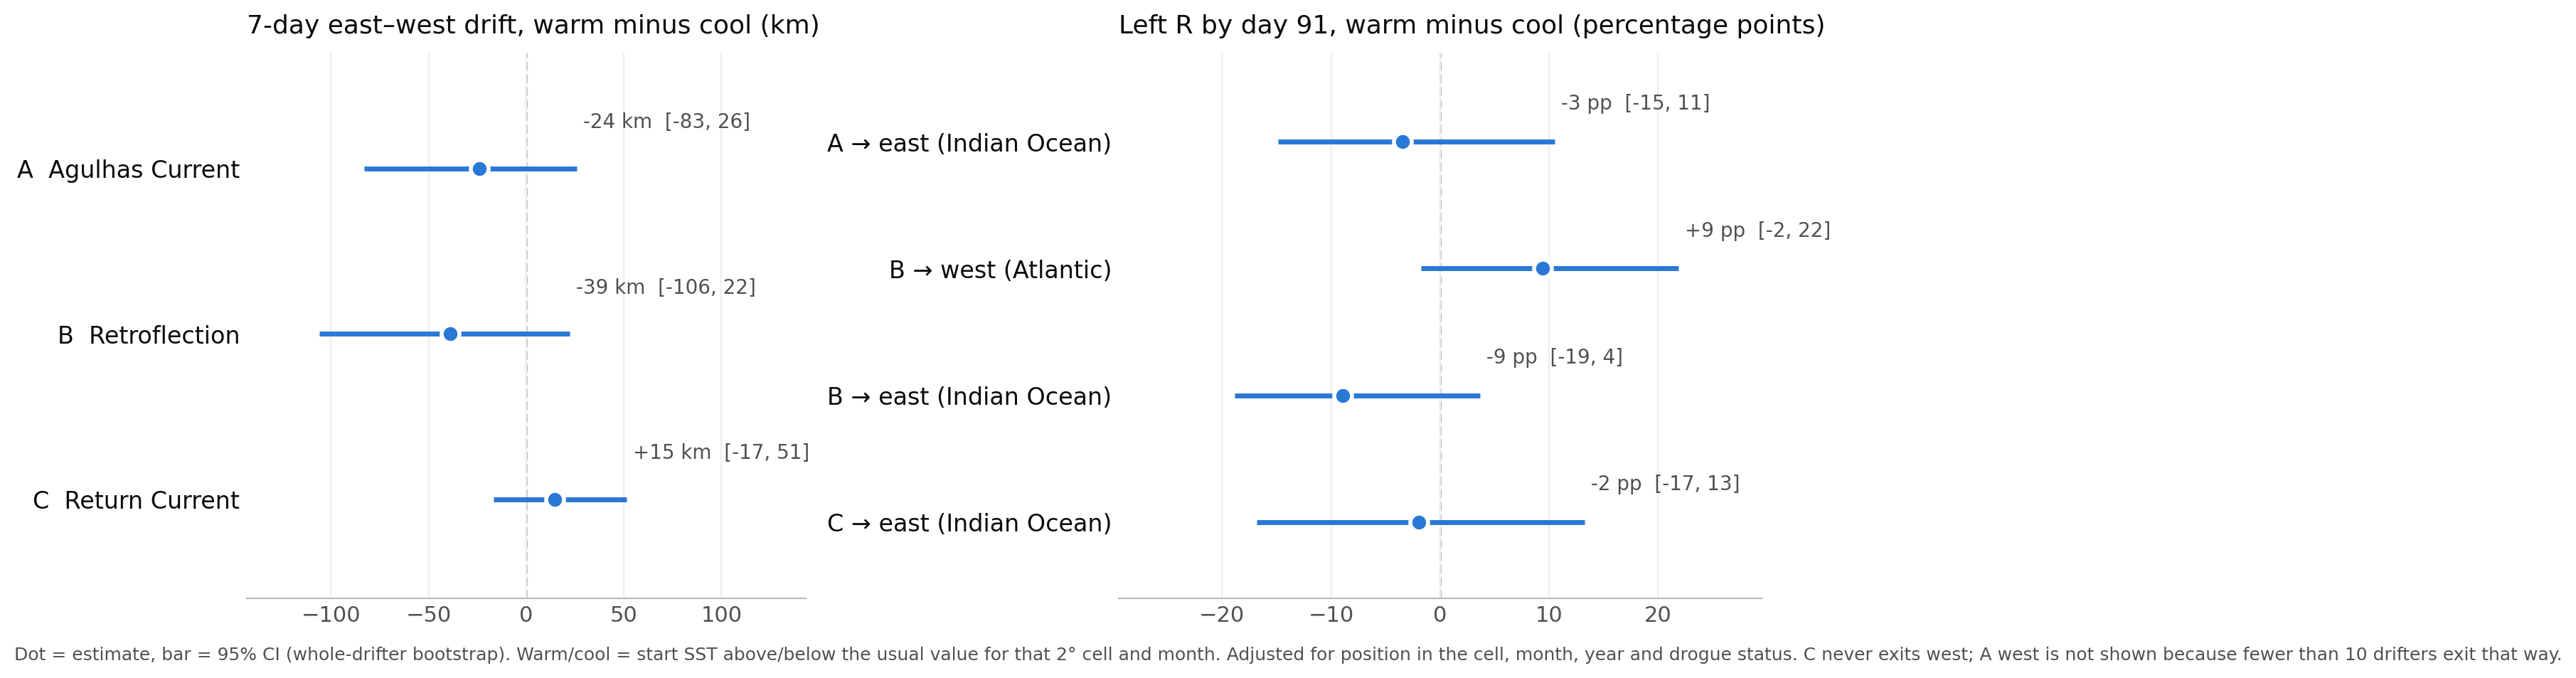

In [ ]:
# Figure: warm minus cool, 7-day drift (left) and 91-day exits (right), numbers from fig_7d / fig_91
import matplotlib.pyplot as plt

INK, INK2, MARK = "#0b0b0b", "#52514e", "#2a78d6"
f7 = pd.DataFrame(fig_7d).set_index("cell").loc[["C", "B", "A"]]
f91 = pd.DataFrame(fig_91)
f91["label"] = f91.cell + " \u2192 " + f91.side.map({"west": "west (Atlantic)", "east": "east (Indian Ocean)"})
order91 = ["C → east (Indian Ocean)", "B → east (Indian Ocean)", "B → west (Atlantic)",
           "A → east (Indian Ocean)", "A → west (Atlantic)"]
f91 = f91.set_index("label").loc[[l for l in order91 if l in f91.label.values]]   # skip anything not estimated
names7 = {"A": "A  Agulhas Current", "B": "B  Retroflection", "C": "C  Return Current"}

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), dpi=200, gridspec_kw={"width_ratios": [1, 1.15]})
panels = [(axes[0], f7, [names7[c] for c in f7.index], "km", "7-day east\u2013west drift, warm minus cool (km)"),
          (axes[1], f91, list(f91.index), "pp", "Left R by day 91, warm minus cool (percentage points)")]
for ax, d, labels, unit, title in panels:
    y = np.arange(len(d))
    ax.axvline(0, color="#bbbbbb", lw=1.2, ls="--", zorder=0)
    ax.hlines(y, d.lo, d.hi, color=MARK, lw=2.5, zorder=2)
    ax.plot(d.est, y, "o", ms=9, color=MARK, mec="white", mew=2, zorder=3)
    for yi, (e, lo, hi) in enumerate(zip(d.est, d.lo, d.hi)):
        ax.text(hi, yi + 0.22, f" {e:+.0f} {unit}  [{lo:.0f}, {hi:.0f}]", fontsize=10, color=INK2, va="bottom")
    ax.set_yticks(y)
    ax.set_yticklabels(labels, fontsize=12, color=INK)
    ax.set_ylim(-0.6, len(d) - 0.3)
    ax.set_title(title, fontsize=13, color=INK, loc="left", pad=10)
    ax.tick_params(axis="x", labelsize=11, colors=INK2, length=0)
    ax.tick_params(axis="y", length=0)
    ax.grid(axis="x", color="#eeeeee", lw=0.8)
    ax.set_axisbelow(True)
    for s in ["top", "right", "left"]:
        ax.spines[s].set_visible(False)
    ax.spines["bottom"].set_color("#bbbbbb")
    lim = max(abs(d.lo).max(), abs(d.hi).max()) * 1.35
    ax.set_xlim(-lim, lim)

fig.text(0.01, -0.02, "Dot = estimate, bar = 95% CI (whole-drifter bootstrap). Warm/cool = start SST above/below the usual "
         "value for that 2\u00b0 cell and month. Adjusted for position in the cell, month, year and drogue status. "
         "C never exits west; A west is not shown because fewer than 10 drifters exit that way.", fontsize=9, color=INK2)
plt.tight_layout()
plt.savefig("fig_temperature_effect.png", dpi=200, bbox_inches="tight", facecolor="white")
plt.show()


### Checking the seasonal matrix results

Our seasonal analysis estimates 91-day exits from one season's matrix multiplied 13 times. That assumes a drifter stays in the same season for all 91 days, and Section 11 showed the matrix underestimates east exits anyway. So I checked its main findings against what drifters actually did, using the same week-by-week outcomes and censoring correction as above, split by the season of the start date. Only training and validation drifters are used, so the numbers are comparable with the seasonal analysis.

In [ ]:
# 91-day exits by season of the start date, each season vs the rest of the year (same resamples for both)
rng_s = np.random.default_rng(10)
rows = []
for name, cid in cells_abc.items():
    o = chain_weeks(pairs_tv, cid, 13)
    o["season"] = pairs_tv.season.values[o.row.values]
    W = drifter_weights(o.traj.values, 500, rng_s)
    for s_ in ["west", "east"]:
        if name == "C" and s_ == "west":
            continue                                  # nothing from C leaves west
        for sea in ["DJF", "MAM", "JJA", "SON"]:
            m = (o.season == sea).values
            ci_part = lambda w, msk: cum_incidence(o.out.values[msk], o.wk.values[msk], s_, w[msk])
            one = np.ones(len(o))
            est, rest = ci_part(one, m), ci_part(one, ~m)
            diffs = [ci_part(w, m) - ci_part(w, ~m) for w in W]
            lo, hi = 100 * np.nanpercentile(diffs, [2.5, 97.5])
            rows.append({"cell": name, "side": s_, "season": sea, "drifters": o.traj[m].nunique(),
                         "exit_%": round(100 * est, 1), "minus_rest_pp": round(100 * (est - rest), 1),
                         "boot_ci95": f"[{lo:.1f}, {hi:.1f}]", "ci_excludes_0": bool(lo > 0 or hi < 0)})
print("observed exit by day 91, by season of the start date (censoring-corrected)")
print(pd.DataFrame(rows).to_string(index=False))

observed exit by day 91, by season of the start date (censoring-corrected)
cell side season  drifters  exit_%  minus_rest_pp     boot_ci95  ci_excludes_0
   A west    DJF        35     2.5           -3.2  [-10.2, 4.6]          False
   A west    MAM        37     0.5           -5.7 [-13.0, -0.3]           True
   A west    JJA        31     3.4           -1.5   [-9.9, 7.1]          False
   A west    SON        31    13.3           11.4  [-2.2, 34.6]          False
   A east    DJF        35     5.8           -7.1  [-17.2, 6.2]          False
   A east    MAM        37    14.5            5.4  [-6.8, 23.5]          False
   A east    JJA        31    11.5            0.9 [-16.3, 26.5]          False
   A east    SON        31    12.1            1.7 [-11.4, 18.0]          False
   B west    DJF        39    23.3            7.6  [-7.5, 25.4]          False
   B west    MAM        45    12.5           -7.4  [-20.5, 9.6]          False
   B west    JJA        37     5.5          -15.3 [-26.4

**What I take from the seasonal check**
- Only training and validation drifters are used here, so the numbers line up with the seasonal analysis.
- **B, winter starts leave west less often:** −15.3 pp [−26.4, −3.1]. This is the one seasonal result that holds whichever drifters or censoring method I use, so it's the one I'd put on a slide.
- **C, summer starts leave east less often:** −25.0 pp [−49.9, −1.3]. This matches the seasonal analysis, but only 25 drifters start at C in summer and the interval nearly reaches 0, so I'd call it likely rather than certain.
- **A, winter starts leave east more often (+7.6 pp from the seasonal matrix):** observed shows almost no difference (+0.9 pp, CI includes 0), so I wouldn't report it.
- **Spring starts leaving west:** with all drifters this looked like a big effect, but without the test drifters it shrinks (A +11.4 pp, B +14.2 pp) and both intervals include 0. Spring starts at B are also mostly undrogued, which on its own makes drifters leave faster, so I can't separate season from drogue here. I overstated this in my first version.
- These 20 intervals aren't independent tests (the same drifters and the same "rest of year" appear in several of them), so I don't read much into how many exclude 0. A autumn west also excludes 0, but it is 0.5% against about 6%, so very few exits either way.

## 13. Save results

In [ ]:
# Save every number the README uses in one file
results = {
    "dataset": {"name": "NOAA Global Drifter Program hourly dataset v2.01.1",
                "access": "clouddrift.datasets.gdp1h()",
                "citation": "Elipot et al. (2022), doi:10.25921/x46c-3620",
                "boundaries": "inclusive (<=)"},
    "data_audit": audit,
    "pipeline_validation_eac": eac,
    "boxes_2deg": boxes,
    "records_in_R": int(len(in_idx)), "drifters_in_R": int(len(tr)),
    "seven_day_pairs": pairs_summary,
}
with open(os.path.join(OUT, "results.json"), "w") as f:
    json.dump(results, f, indent=2, default=int)
print(f"saved {OUT}/results.json and {OUT}/pairs7.csv")

saved gdp_out/results.json and gdp_out/pairs7.csv
